# SWIGGY END-TO-END DATA PIPELINE & DATA ANALYSIS PROJECT
#### DATA --> SNOWFLAKE --> DBT[BRONZE . SILVER . GOLD] --> PYTHON ANALYSIS --> STREAMLIT --> LLM & RAG CHATBOT

## 1. Imports and notebook setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from snowflake.snowpark import Session
from dotenv import load_dotenv
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

def format_number(value):
    # Format large KPI values in a compact, readable form.
    value = float(value)
    if abs(value) >= 1_000_000:
        return f"{value / 1_000_000:,.2f}M"
    if abs(value) >= 1_000:
        return f"{value / 1_000:,.1f}K"
    return f"{value:,.0f}"
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Snowflake connection

In [2]:
load_dotenv()
conn_params = {
    "account":   os.getenv("SNOWFLAKE_ACCOUNT"),
    "user":      os.getenv("SNOWFLAKE_USER"),
    "password":  os.getenv("SNOWFLAKE_PASSWORD"),
    "role":      "DBT_ROLE",
    "warehouse": "SWIGGY_WH",
    "database":  "SWIGGY",
    "schema":    "MARTS",
}

session = Session.builder.configs(conn_params).create()

session.sql("""
    SELECT
        CURRENT_USER() AS user_name,
        CURRENT_ROLE() AS role_name,
        CURRENT_WAREHOUSE() AS warehouse_name,
        CURRENT_DATABASE() AS database_name,
        CURRENT_SCHEMA() AS schema_name
""").show()

------------------------------------------------------------------------------------
|"USER_NAME"    |"ROLE_NAME"  |"WAREHOUSE_NAME"  |"DATABASE_NAME"  |"SCHEMA_NAME"  |
------------------------------------------------------------------------------------
|SNOWBISWAJEET  |DBT_ROLE     |SWIGGY_WH         |SWIGGY           |MARTS          |
------------------------------------------------------------------------------------



In [3]:
session.sql("SHOW TABLES IN SCHEMA SWIGGY.MARTS").show()

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"created_on"                      |"name"                       |"database_name"  |"schema_name"  |"kind"     |"comment"  |"cluster_by"  |"rows"    |"bytes"    |"owner"   |"retention_time"  |"automatic_clustering"  |"change_tracking"  |"search_optimization"  |"search_optimization_progress"  |"search_optimization_bytes"  |"is_external"  |"enable_schema_evolution"  |"owner_role_type"  |"is_event"  |"is_hybrid"  |"is_iceberg"  |"is_dynamic"  |"is_immutable"  |"is_interactive"  |"

## 3. Load the Gold layer tables

In [4]:
table_to_load = [
    "DIM_RESTAURANTS", 
    "DIM_CUSTOMER",
    "DIM_FOOD", 
    "DIM_DATE", 
    "MART_DAILY_CITY_REVENUE", 
    "MART_DELIVERY_SLA", 
    "MART_RESTAURANT_PERFORMANCE",
    "FACT_ORDERS",
    "FACT_ORDER_ITEMS",]

In [5]:
dataframes = {}
for table in table_to_load:
    dataframes[table] = session.table(f"SWIGGY.MARTS.{table}").to_pandas()
    print(f"{table}: {dataframes[table].columns.tolist()}")

DIM_RESTAURANTS: ['RESTAURANT_ID', 'RESTAURANT_NAME', 'CITY', 'CUISINE', 'RATING', 'RATING_COUNT', 'COST']
DIM_CUSTOMER: ['CUSTOMER_ID', 'CUSTOMER_NAME', 'EMAIL', 'AGE', 'AGE_SEGMENT', 'GENDER', 'MARITAL_STATUS', 'OCCUPATION', 'MONTHLY_INCOME', 'EDUCATION', 'FAMILY_SIZE']
DIM_FOOD: ['F_ID', 'FOOD_NAME', 'VEG_OR_NON_VEG']
DIM_DATE: ['DATE_DAY', 'YEAR', 'MONTH', 'MONTH_NAME', 'DAY_NAME', 'IS_WEEKEND']
MART_DAILY_CITY_REVENUE: ['ORDER_DATE', 'CITY', 'ORDERS', 'DELIVERED_ORDERS', 'CANCEL_RATE', 'GMV', 'AOV']
MART_DELIVERY_SLA: ['CITY', 'ORDER_HOUR', 'DELIVERED_ORDERS', 'P50', 'P90']
MART_RESTAURANT_PERFORMANCE: ['RESTAURANT_ID', 'RESTAURANT_NAME', 'CITY', 'CUISINE', 'ORDERS', 'REVENUE', 'AVG_CUSTOMER_RATING', 'AVG_DELIVERY_MIN']
FACT_ORDERS: ['ORDER_ID', 'ORDER_TIMESTAMP', 'ORDER_DATE', 'CUSTOMER_ID', 'RESTAURANT_ID', 'CITY', 'CUISINE', 'PAYMENT_METHOD', 'ORDER_STATUS', 'IS_DELIVERED', 'ITEMS_COUNT', 'SALES_QTY', 'SUBTOTAL', 'DISCOUNT', 'DELIVERY_FEE', 'GST', 'SALES_AMOUNT', 'CUSTOMER_RATI

## 4. Initial dataframe profiling
### 4.1 Size, missing values and duplicates

In [6]:
#1. prepared a function to count the duplicated values on all tables
def count_duplicates(df):
    return int(df.duplicated().sum())

#2. preared a summary table to display the shape, duplicates value, and missin values
summary = pd.DataFrame({
    columns : {"rows": len(df), "columns": df.shape[1],
           "missing cells": int(df.isna().sum().sum()),
           "duplicate rows": count_duplicates(df)}
    for columns, df in dataframes.items()
}).T
display(summary)

#3. displayed the columns which contain the missing values
for df_name, df in dataframes.items():
    null_value = df.isna().sum()
    miss = null_value[null_value > 0]
    if len(miss) > 0:
        print(f"\nColumns with missing value for {df_name}")
        display(pd.DataFrame({"missing": miss, "percent": miss / len(df) * 100}))

,rows,columns,missing cells,duplicate rows
DIM_RESTAURANTS,148541,7,174516,0
DIM_CUSTOMER,100000,11,0,0
DIM_FOOD,371560,3,0,0
DIM_DATE,1096,6,0,0
MART_DAILY_CITY_REVENUE,433643,7,0,0
MART_DELIVERY_SLA,6616,5,0,0
MART_RESTAURANT_PERFORMANCE,148541,8,38226,0
FACT_ORDERS,10000000,19,9708094,0
FACT_ORDER_ITEMS,22998179,10,0,0



Columns with missing value for DIM_RESTAURANTS


,missing,percent
RESTAURANT_NAME,86,0.06
CUISINE,99,0.07
RATING,87100,58.64
RATING_COUNT,87100,58.64
COST,131,0.09



Columns with missing value for MART_RESTAURANT_PERFORMANCE


,missing,percent
RESTAURANT_NAME,86,0.06
CUISINE,99,0.07
AVG_CUSTOMER_RATING,38041,25.61



Columns with missing value for FACT_ORDERS


,missing,percent
CUISINE,3635,0.04
CUSTOMER_RATING,9704459,97.04


In [7]:
#4. checking the dtypes of tables columns
for df_name, df in dataframes.items():
    print(f"\ndtypes for {df_name}")
    print(df.dtypes)


dtypes for DIM_RESTAURANTS
RESTAURANT_ID        int32
RESTAURANT_NAME     object
CITY                object
CUISINE             object
RATING             float64
RATING_COUNT       float64
COST               float64
dtype: object

dtypes for DIM_CUSTOMER
CUSTOMER_ID        int32
CUSTOMER_NAME     object
EMAIL             object
AGE                 int8
AGE_SEGMENT       object
GENDER            object
MARITAL_STATUS    object
OCCUPATION        object
MONTHLY_INCOME    object
EDUCATION         object
FAMILY_SIZE         int8
dtype: object

dtypes for DIM_FOOD
F_ID              object
FOOD_NAME         object
VEG_OR_NON_VEG    object
dtype: object

dtypes for DIM_DATE
DATE_DAY      object
YEAR           int16
MONTH           int8
MONTH_NAME    object
DAY_NAME      object
IS_WEEKEND      bool
dtype: object

dtypes for MART_DAILY_CITY_REVENUE
ORDER_DATE           object
CITY                 object
ORDERS                int16
DELIVERED_ORDERS      int16
CANCEL_RATE         float64
GMV     

### 4.2 fix the dtypes

In [8]:
num_cols = ["ITEMS_COUNT", "SALES_QTY", "SUBTOTAL", "DISCOUNT", "DELIVERY_FEE", "GST",
            "SALES_AMOUNT", "CUSTOMER_RATING", "DELIVERY_TIME_MIN"]

for cols in num_cols:
    dataframes['FACT_ORDERS'][cols] = pd.to_numeric(dataframes['FACT_ORDERS'][cols], errors="coerce")

dataframes['FACT_ORDERS']["ORDER_DATE"] = pd.to_datetime(dataframes['FACT_ORDERS']["ORDER_DATE"])
dataframes['FACT_ORDERS']["ORDER_TIMESTAMP"] = pd.to_datetime(dataframes['FACT_ORDERS']["ORDER_TIMESTAMP"])
dataframes['MART_DAILY_CITY_REVENUE']["ORDER_DATE"] = pd.to_datetime(dataframes['MART_DAILY_CITY_REVENUE']["ORDER_DATE"])

for cols in ["CUSTOMER_ID", "RESTAURANT_ID"]:
    dataframes['FACT_ORDERS'][cols] = pd.to_numeric(dataframes['FACT_ORDERS'][cols]).astype("int64")
dataframes['MART_RESTAURANT_PERFORMANCE']["RESTAURANT_ID"] = pd.to_numeric(dataframes['MART_RESTAURANT_PERFORMANCE']["RESTAURANT_ID"]).astype("int64")



### 4.3 Quality check

In [9]:
print("ORDER_STATUS values :", dataframes['FACT_ORDERS']["ORDER_STATUS"].unique())
print("IS_DELIVERED values :", dataframes['FACT_ORDERS']["IS_DELIVERED"].unique())
print("CANCEL_RATE values  :", dataframes['MART_DAILY_CITY_REVENUE']["CANCEL_RATE"].unique())

# Is SALES_AMOUNT just the sum of its own parts? (important for choosing what to predict)
gap = (dataframes['FACT_ORDERS']["SUBTOTAL"] - dataframes['FACT_ORDERS']["DISCOUNT"] + dataframes['FACT_ORDERS']["DELIVERY_FEE"] + dataframes['FACT_ORDERS']["GST"] - dataframes['FACT_ORDERS']["SALES_AMOUNT"]).abs()
print(f"\nSALES_AMOUNT = SUBTOTAL - DISCOUNT + DELIVERY_FEE + GST ?  largest gap = {gap.max():.4f}, "
      f"orders with gap > 0.01 = {(gap > 0.01).sum():,}")

print("Orders with SUBTOTAL = 0 :", f"{(dataframes['FACT_ORDERS']['SUBTOTAL'] == 0).sum():,}")
print("5 largest restaurant COST:", dataframes['DIM_RESTAURANTS']["COST"].nlargest(5).tolist())
print("Median restaurant COST   :", dataframes['DIM_RESTAURANTS']["COST"].median())

ORDER_STATUS values : ['Delivered']
IS_DELIVERED values : [ True]
CANCEL_RATE values  : [0.]

SALES_AMOUNT = SUBTOTAL - DISCOUNT + DELIVERY_FEE + GST ?  largest gap = 0.0000, orders with gap > 0.01 = 0
Orders with SUBTOTAL = 0 : 31
5 largest restaurant COST: [300350.0, 8000.0, 6000.0, 5023.0, 5000.0]
Median restaurant COST   : 250.0


#### Insights:
- **Every order is `Delivered`** (one value in 10,000,000 rows) and `CANCEL_RATE` is 0 in all 433,643 city-days. Cancelled orders are not in the Gold layer, so **cancellations cannot be analysed**. Check whether your dbt Silver model filters them out.
- **`SALES_AMOUNT` is built from its parts.** The gap line above should show about 0. If it does, then predicting `SALES_AMOUNT` from `SUBTOTAL`, `DISCOUNT`, `DELIVERY_FEE` or `GST` is just arithmetic. That is why the model in section 10 predicts **city revenue from past patterns** instead.
- **Zero-value orders:** `SUBTOTAL` has a minimum of 0 although the smallest `SALES_AMOUNT` is 20. Orders with a zero subtotal exist (the count is printed above) and are worth asking your data source about.
- **One clear error:** the largest restaurant `COST` is 300,350 while the median is 250. We fix this in section 9.

## EXPLORATORY DATA ANALYSIS (EDA)
### 5.1 Distribution analysis & Outlier Detection (#. Univariate Analysis)

In [10]:
def show_dist(df, col, title=None, discrete=False, log=False):
    """Histogram (left) and box plot (right) for one column."""
    values = df[col].dropna()
    fig, ax = plt.subplots(1, 2, figsize=(7,3))
    sns.histplot(values, discrete=discrete, ax=ax[0])
    sns.boxplot(x=values, ax=ax[1])
    if log:
        ax[0].set_xscale("log")
        ax[1].set_xscale("log")
    fig.suptitle(title or col, fontsize=14)
    plt.tight_layout()
    plt.show()

,SUBTOTAL,DISCOUNT,DELIVERY_FEE,SALES_AMOUNT
count,"10,000,000.00","10,000,000.00","10,000,000.00","10,000,000.00"
mean,482.09,26.49,23.11,501.49
std,458.40,38.25,18.90,453.86
min,0.00,0.00,0.00,20.00
50%,355.00,9.15,20.00,384.90
75%,615.00,38.90,40.00,606.90
99%,"2,204.00",150.00,50.00,"2,239.65"
max,"27,660.00",150.00,50.00,"28,885.50"


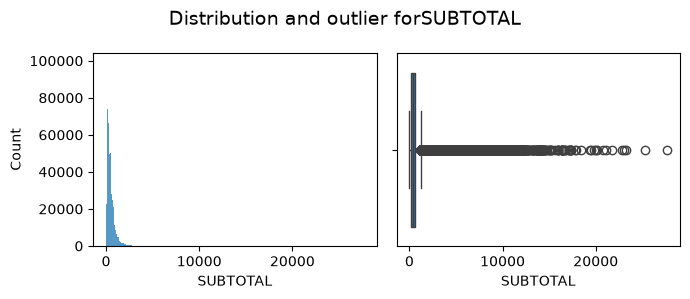

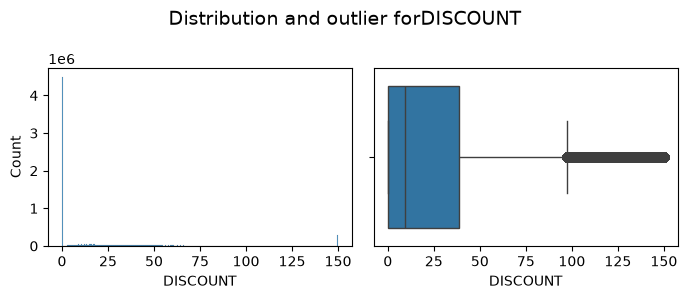

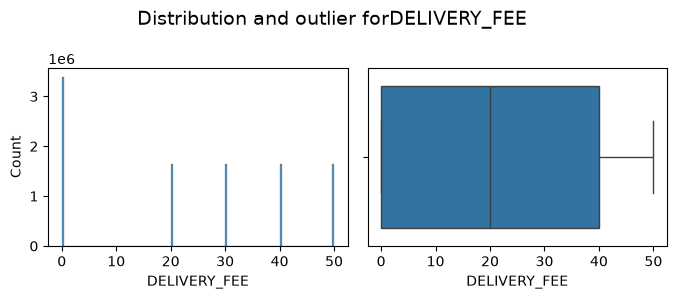

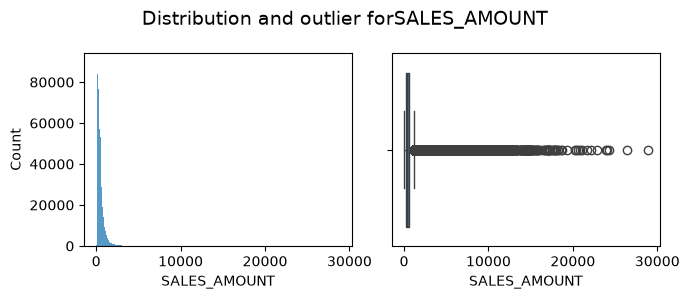

In [11]:
# lets apply the distribution plot and detect the outliers
## Distribution plot for "FACT_ORDERS" tables
#### we have to check Financial distribution & high-value order outliers for SUBTOTAL, DISCOUNT, DELIVERY_FEE, SALES_AMOUNT
mony_cols = dataframes['FACT_ORDERS'][['SUBTOTAL', 'DISCOUNT', 'DELIVERY_FEE', 'SALES_AMOUNT']]
display(mony_cols.describe(percentiles=[.5, .75, .99]))

for cols in mony_cols:
    show_dist(dataframes['FACT_ORDERS'], cols, title=f"Distribution and outlier for{cols}")


### 5.2 Order size, delivery time & rating

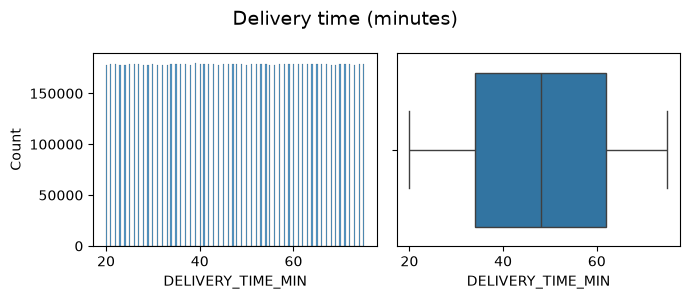

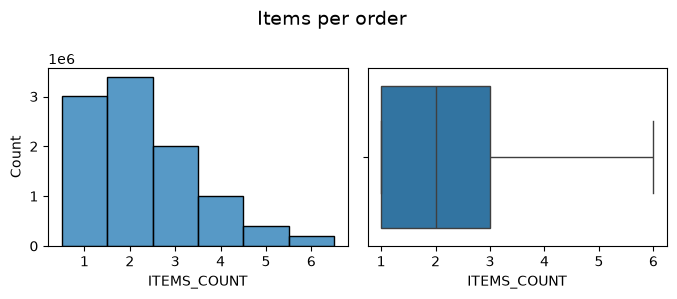

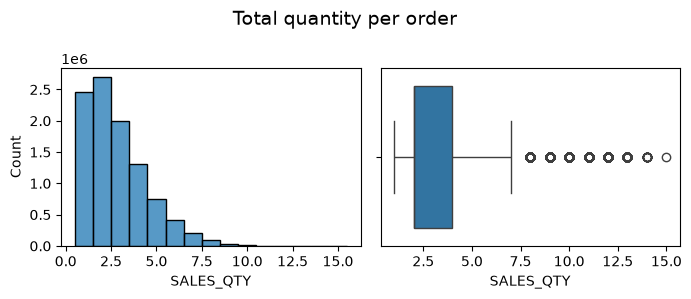

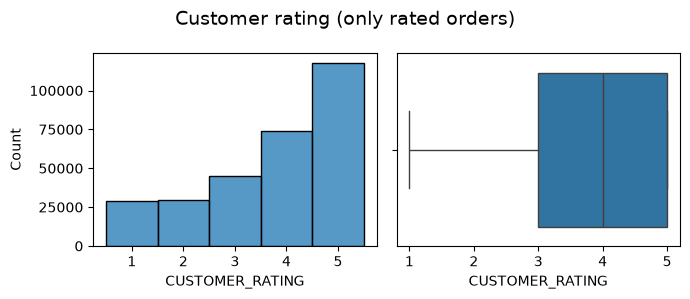

In [12]:
# distribution plot for DELIVERY_TIME_MIN, ITEMS_COUNT, SALES_QTY, CUSTOMER_RATING in "FACT_ORDERS" table
show_dist(dataframes['FACT_ORDERS'], "DELIVERY_TIME_MIN", "Delivery time (minutes)")
show_dist(dataframes['FACT_ORDERS'], "ITEMS_COUNT", "Items per order", discrete=True)
show_dist(dataframes['FACT_ORDERS'], "SALES_QTY", "Total quantity per order", discrete=True)
show_dist(dataframes['FACT_ORDERS'], "CUSTOMER_RATING", "Customer rating (only rated orders)", discrete=True)

### 5.3 Customer table distribution

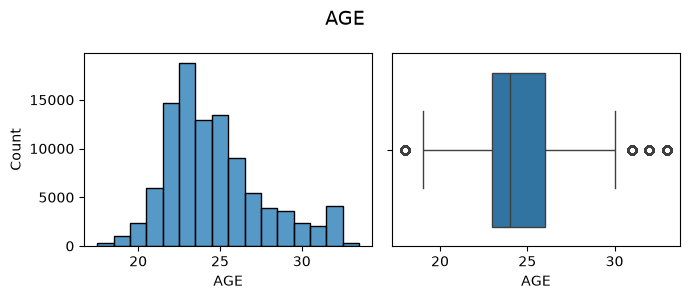

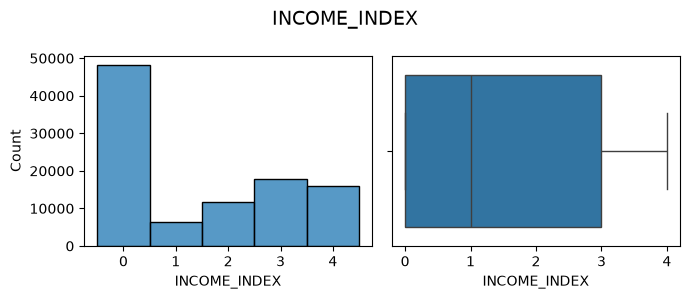

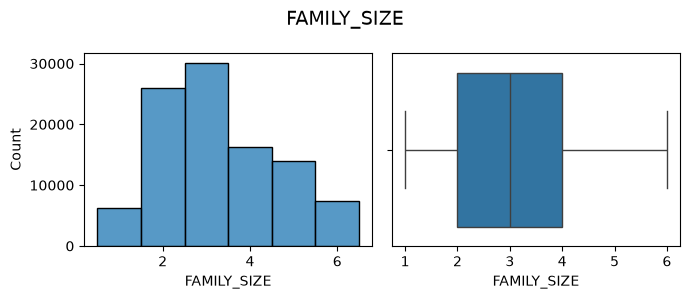


AGE_SEGMENT (% of customers)
AGE_SEGMENT
Gen Z        55.90
Millennial   44.10

GENDER (% of customers)
GENDER
Male     57.20
Female   42.80

MARITAL_STATUS (% of customers)
MARITAL_STATUS
Single              69.10
Married             27.80
Prefer not to say    3.10

OCCUPATION (% of customers)
OCCUPATION
Student          53.40
Employee         30.40
Self Employeed   13.90
House wife        2.30

EDUCATION (% of customers)
EDUCATION
Graduate        45.60
Post Graduate   44.90
Ph.D             5.90
School           3.10
Uneducated       0.50

MONTHLY_INCOME (% of customers)
MONTHLY_INCOME
No Income         48.20
25001 to 50000    17.80
More than 50000   16.00
10001 to 25000    11.60
Below Rs.10000     6.40


In [13]:
## Distribution plot for "DIM_CUSTOMER" tables
#### we have to check Financial distribution & high-value order outliers for AGE, MONTHLY_INCOME, FAMILY_SIZE
income_mapping = {
    'No Income': 0,
    'Below Rs.10000': 1,
    '10001 to 25000': 2,
    '25001 to 50000': 3,
    'More than 50000': 4
}
dataframes['DIM_CUSTOMER']['INCOME_INDEX'] = dataframes['DIM_CUSTOMER']['MONTHLY_INCOME'].map(income_mapping)
assert dataframes['DIM_CUSTOMER']['INCOME_INDEX'].notna().all(), "Some income index are missing"
for cols in ['AGE', 'INCOME_INDEX', 'FAMILY_SIZE']:
    show_dist(dataframes['DIM_CUSTOMER'], cols, discrete=True)

for col in ["AGE_SEGMENT", "GENDER", "MARITAL_STATUS", "OCCUPATION", "EDUCATION", "MONTHLY_INCOME"]:
    print(f"\n{col} (% of customers)")
    print((dataframes['DIM_CUSTOMER'][col].value_counts(normalize=True) * 100).round(1).to_string())


#### Insights:
- **A young, narrow customer base.** Ages run from 18 to 33 (mean 24.6) with most customers between 22 and 25. 55.9% are Gen Z, 53.4% are students and 69.1% are single.
- **Income:** 48.2% report "No Income" (income level 0), which fits a student-heavy base.
- Other splits: 57.2% male, 45.6% graduates, family size 1 to 6 (mean 3.3, with 3 and 2 the most common).
- **What it means:** because the customers are so similar to each other, customer demographics may explain little of the differences between cities. Section 6.5 tests this.

### 5.4 Restaurant table distribution

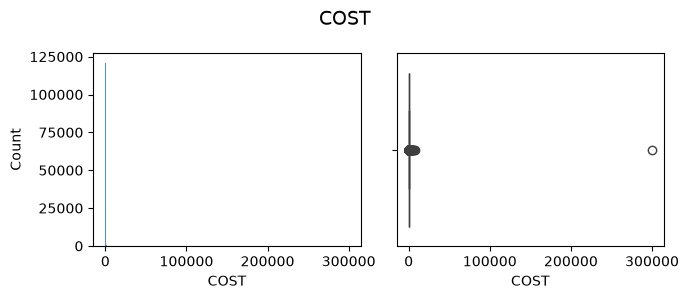

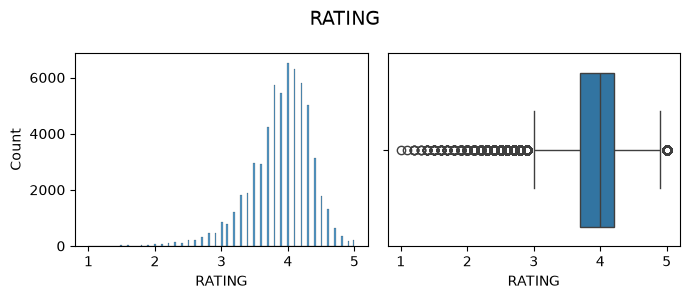

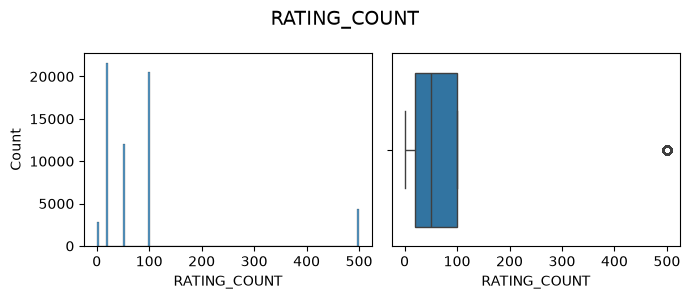

Restaurants with a rating: 41.4%
Most common RATING_COUNT values: {20.0: 21636, 100.0: 20548, 50.0: 12009, 500.0: 4396, 1.0: 2739}


In [14]:
## Distribution plot for "DIM_RASTAURANTS" tables
#### we have to check the distribution for COST, RATING, RATING_COUNT
for cols in ['COST', 'RATING', 'RATING_COUNT']:
    show_dist(dataframes['DIM_RESTAURANTS'], cols)

print("Restaurants with a rating:", f"{dataframes['DIM_RESTAURANTS']['RATING'].notna().mean() * 100:.1f}%")
print("Most common RATING_COUNT values:", dataframes['DIM_RESTAURANTS']["RATING_COUNT"].value_counts().head(5).to_dict())

#### Insights:
- **`COST`** has median 250 and mean 288, but the largest value is 300,350, which is clearly an error and flattens the whole plot. Everything else is below about 8,000.
- **`RATING`** is left-skewed (mean 3.89, median 4.0) and only 41.4% of restaurants have one.
- **`RATING_COUNT`** is stuck on a few values (20, 50, 100, 500), so it looks bucketed or capped. The value 500 is flagged as an "outlier" by the box plot, but it is just the top bucket.

### 5.5 DAILY_CITY_REVENUE and DELIVERY mart tables distribution

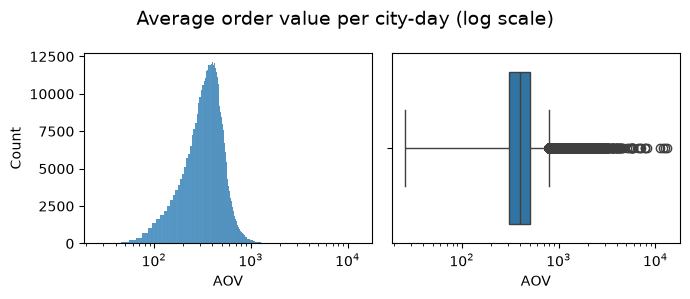

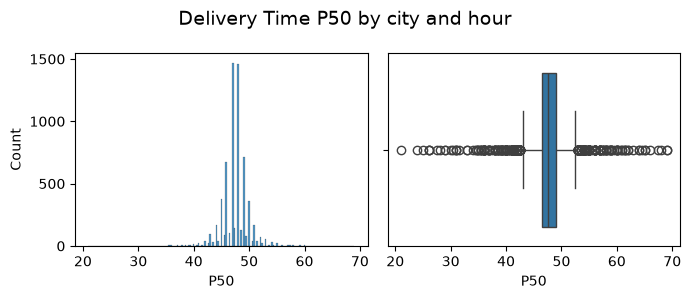

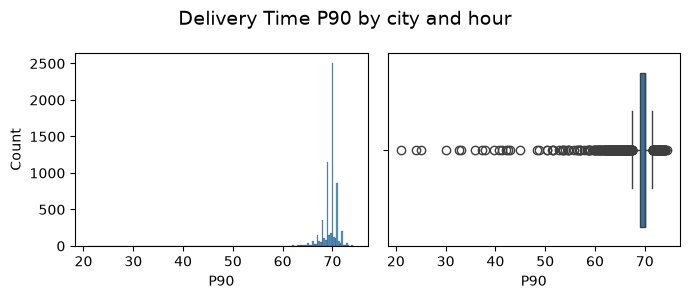

Orders per city-day:
count   433,643.00
mean         23.10
std         102.70
min           1.00
25%           2.00
50%           4.00
75%          10.00
90%          28.00
max       1,331.00


In [15]:
show_dist(dataframes['MART_DAILY_CITY_REVENUE'], "AOV", "Average order value per city-day (log scale)", log=True)
for cols in ["P50", "P90"]:
    show_dist(dataframes['MART_DELIVERY_SLA'], cols, f"Delivery Time {cols} by city and hour")

print("Orders per city-day:")
print(dataframes['MART_DAILY_CITY_REVENUE']["ORDERS"].describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())

#### Insights:
- **Most city-days are tiny.** The median city-day has 4 orders (25th percentile: 2, 75th: 10), while the busiest has 1,331. Daily revenue for small cities is mostly random noise. This matters for the model.
- **AOV** is right-skewed; a few city-days with one big order reach 13,000.
- **Delivery time is almost identical everywhere:** P50 averages 47.5 (standard deviation 2.7) and P90 averages 69.4 (standard deviation 2.5) across all city-hours. Cities do not differ much in delivery speed.
- `CANCEL_RATE` is not plotted because it is always 0.

## 6. Business views: cities, payments, cuisines, restaurants, customers

### 6.1 Cities and payment methods

,CITY,Total_Orders,Total_Revenue,Avg_Basket_Size,SHARE_%
45,Bangalore,1106178,"608,065,944.78",531.27,12.13
148,Delhi,851171,"461,200,277.03",523.77,9.20
120,Chennai,778888,"402,913,964.61",498.58,8.03
222,Hyderabad,731339,"380,563,991.44",501.70,7.59
418,Pune,733802,"380,149,131.29",499.17,7.58
290,Kolkata,559736,"306,135,600.41",528.01,6.10
359,Mumbai,385487,"244,220,181.74",616.35,4.87
6,Ahmedabad,217839,"124,620,164.21",553.93,2.49
116,Chandigarh,215287,"98,816,702.45",439.25,1.97
94,Bikaner,123192,"75,108,042.54",592.96,1.50


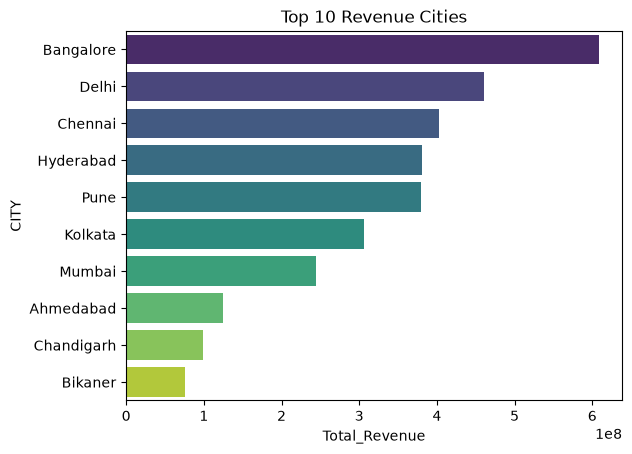

Insight: 552 cities in total. Top city = Bangalore (12.1% of revenue). The top 5 cities = 44.5% of revenue.


,PAYMENT_METHOD,ORDERS,AVG_ORDER,SHARE_%
3,UPI,5499026,501.19,54.99
0,Cash on Delivery,1501030,501.92,15.01
1,Credit Card,1499653,501.56,15.00
2,Debit Card,1000441,502.25,10.00
4,Wallet,499850,501.74,5.00


In [16]:
# lets ckeck the top 10 revenue city
city_performance = dataframes['FACT_ORDERS'].groupby('CITY').agg(
    Total_Orders=('ORDER_ID', 'count'),
    Total_Revenue=('SALES_AMOUNT', 'sum'),
    Avg_Basket_Size=('SUBTOTAL', 'mean')
).reset_index()
city_performance["SHARE_%"] = city_performance["Total_Revenue"] / city_performance["Total_Revenue"].sum() * 100
top_10_revenue_cities = city_performance.nlargest(10, 'Total_Revenue')
display(top_10_revenue_cities)
sns.barplot(data=top_10_revenue_cities, x="Total_Revenue", y="CITY", hue="CITY", legend=False, palette="viridis")
plt.title("Top 10 Revenue Cities")
plt.show()

top5 = top_10_revenue_cities.head(5)["SHARE_%"].sum()
print(f"Insight: {len(city_performance)} cities in total. Top city = {top_10_revenue_cities.iloc[0]['CITY']} "
      f"({top_10_revenue_cities.iloc[0]['SHARE_%']:.1f}% of revenue). The top 5 cities = {top5:.1f}% of revenue.")

payment_method = dataframes['FACT_ORDERS'].groupby("PAYMENT_METHOD").agg(
    ORDERS=("ORDER_ID", "count"), AVG_ORDER=("SALES_AMOUNT", "mean")).reset_index()
payment_method["SHARE_%"] = payment_method["ORDERS"] / payment_method["ORDERS"].sum() * 100
display(payment_method.sort_values("ORDERS", ascending=False))

#### Insights:
- **Bangalore leads** with 1,106,178 orders and about 608M revenue, followed by Delhi (461M), Chennai (403M), Hyderabad (381M) and Pune (380M). Kolkata (306M) and Mumbai (244M) come next.
- **Mumbai has the highest average basket** (subtotal 616 vs about 500 in most top cities) but fewer orders (385,487).
- **Revenue is concentrated:** the top 5 cities make up about 44.5% of all revenue, and 552 cities share the rest. The model has to handle a few big cities and a long tail of small ones.
- **UPI dominates payments** with 5,499,026 orders (55%).

### 6.2 Cuisines performance

In [17]:
## lets check top 10 cuisine performance by revenue
cuisine_performance = dataframes['FACT_ORDERS'].groupby('CUISINE').agg(
    Total_Orders=('ORDER_ID', 'count'),
    Total_Revenue=('SALES_AMOUNT', 'sum'),
    Avg_Basket_Size=('SUBTOTAL', 'mean')
).reset_index()
top_10_cuisines = cuisine_performance.nlargest(10, 'Total_Revenue')
display(top_10_cuisines)

,CUISINE,Total_Orders,Total_Revenue,Avg_Basket_Size
1517,"North Indian,Chinese",465234,"252,341,018.78",524.71
1039,"Indian,Chinese",291638,"157,188,590.28",521.36
1020,Indian,341708,"152,594,670.84",425.83
1499,North Indian,300241,"139,990,873.52",446.08
537,Chinese,262710,"125,820,301.97",458.80
1646,Pizzas,193047,"114,231,814.52",577.28
1868,South Indian,257854,"95,008,362.05",344.63
193,Bakery,147401,"83,220,713.01",544.49
593,"Chinese,North Indian",156087,"79,862,258.26",493.28
206,"Bakery,Desserts",147212,"77,479,473.40",507.48


### 6.3 Cities Average order value

In [18]:
# lets check the top 10 city of Average order value
city_mart_summary = dataframes['MART_DAILY_CITY_REVENUE'].groupby('CITY').agg(
    ORDERS=("ORDERS", "sum"), 
    GMV=("GMV", "sum"),
    ACTIVE_DAYS=("ORDER_DATE", "nunique")).reset_index()
city_mart_summary['ORDERS_PER_DAY'] = city_mart_summary['ORDERS'] / city_mart_summary['ACTIVE_DAYS']
city_mart_summary['AOV'] = city_mart_summary['GMV'] / city_mart_summary['ORDERS']

MIN_ORDERS = 5000                               # ignore tiny cities (their AOV is mostly noise)
big = city_mart_summary[city_mart_summary["ORDERS"] >= MIN_ORDERS]
display(big.nlargest(10, "AOV"))

overall = dataframes['MART_DAILY_CITY_REVENUE']["GMV"].sum() / dataframes['MART_DAILY_CITY_REVENUE']["ORDERS"].sum()
print(f"Insight: overall AOV = {overall:,.2f}, but the simple average of daily AOVs = {dataframes['MART_DAILY_CITY_REVENUE']['AOV'].mean():,.2f}.")
print(f"{len(big)} of {len(city_mart_summary)} cities have at least {MIN_ORDERS:,} orders.")

,CITY,ORDERS,GMV,ACTIVE_DAYS,ORDERS_PER_DAY,AOV
395,North-goa,27191,"20,648,399.27",912,29.81,759.38
9,Ajmer,10331,"7,694,817.29",912,11.33,744.83
111,Central-goa,33014,"22,307,430.77",912,36.20,675.70
496,Sultanpur,19417,"12,985,948.26",912,21.29,668.79
359,Mumbai,385487,"244,220,181.74",912,422.68,633.54
14,Allahabad,33805,"21,164,753.37",912,37.07,626.08
21,Amritsar,30501,"19,077,698.95",912,33.44,625.48
23,Anantapur,13456,"8,231,146.67",912,14.75,611.71
94,Bikaner,123192,"75,108,042.54",912,135.08,609.68
29,Asansol,9737,"5,706,893.17",912,10.68,586.10


Insight: overall AOV = 501.49, but the simple average of daily AOVs = 419.58.
203 of 552 cities have at least 5,000 orders.


### 6.4 Top Restaurant and the Revenue PowerHouse

Revenue per restaurant:
count     148,541.00
mean       33,761.00
std        45,012.00
min         1,913.00
25%        12,651.00
50%        18,883.00
75%        35,892.00
max     1,172,960.00

Number of ratings per restaurant:
count   148,541.00
mean          2.00
std           2.50
min           0.00
25%           0.00
50%           1.00
75%           3.00
max          26.00


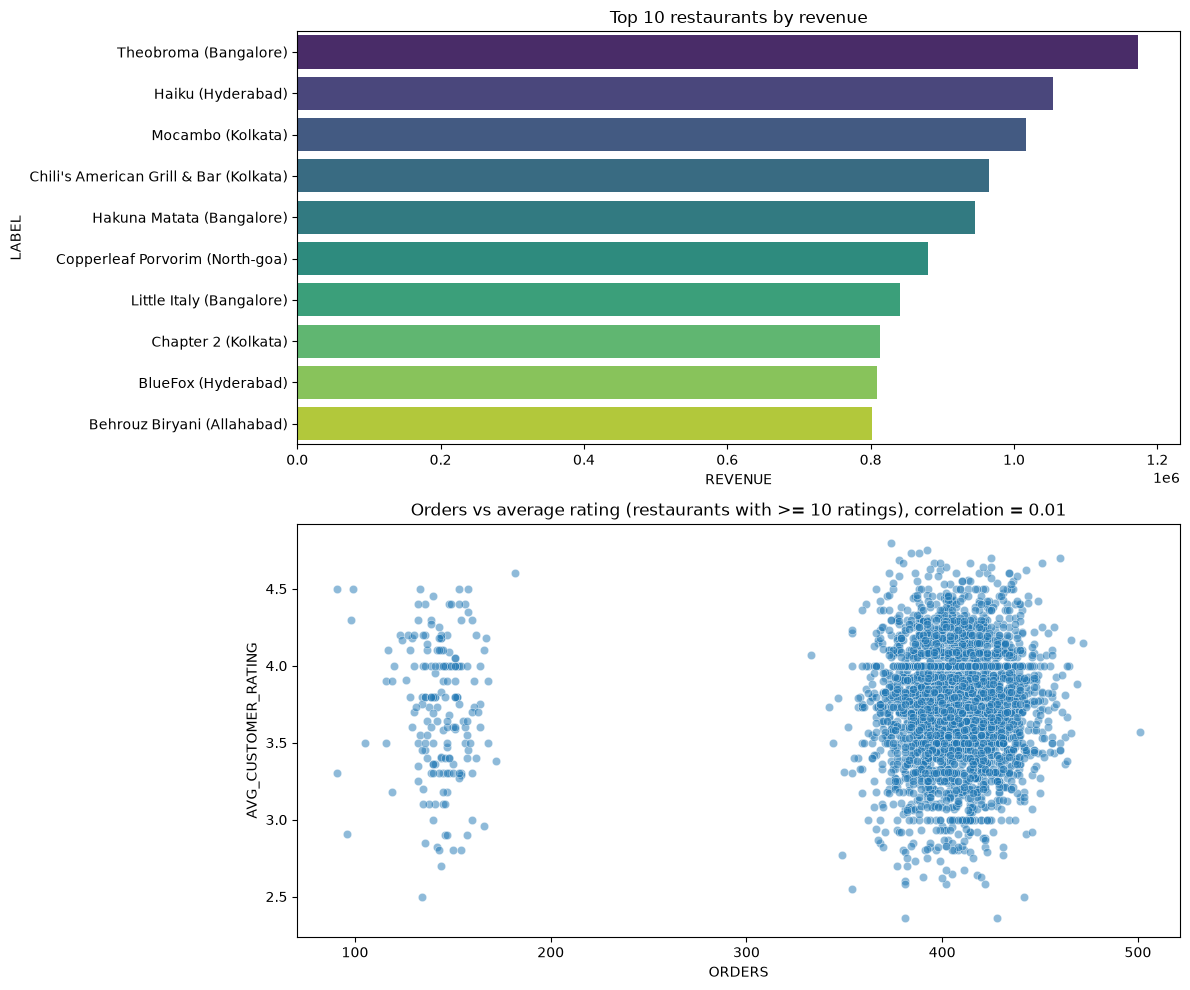

Insight: only 3,497 of 148,541 restaurants have at least 10 ratings.


In [19]:
rating_count = dataframes['FACT_ORDERS'].groupby("RESTAURANT_ID")["CUSTOMER_RATING"].count().rename("RATED_ORDERS").reset_index()
top_performance = dataframes['MART_RESTAURANT_PERFORMANCE'].merge(rating_count, on="RESTAURANT_ID", how="left")
top_performance['RATED_ORDERS'] = top_performance['RATED_ORDERS'].fillna(0)

print("Revenue per restaurant:");  print(top_performance["REVENUE"].describe().round(0).to_string())
print("\nNumber of ratings per restaurant:"); print(top_performance["RATED_ORDERS"].describe().round(1).to_string())

top10_performer = top_performance.nlargest(10, "REVENUE").copy()
top10_performer["LABEL"] = top10_performer["RESTAURANT_NAME"].fillna("Unknown") + " (" + top10_performer["CITY"] + ")"

MIN_RATINGS = 10
reliable = top_performance[(top_performance["RATED_ORDERS"] >= MIN_RATINGS) & top_performance["AVG_CUSTOMER_RATING"].notna()]

fig, ax = plt.subplots(2, 1, figsize=(12, 10))
sns.barplot(data=top10_performer, x="REVENUE", y="LABEL", hue="LABEL", legend=False, palette="viridis", ax=ax[0])
ax[0].set_title("Top 10 restaurants by revenue")
if len(reliable) > 2:
    sns.scatterplot(data=reliable, x="ORDERS", y="AVG_CUSTOMER_RATING", alpha=0.5, ax=ax[1])
    rho = reliable[["ORDERS", "AVG_CUSTOMER_RATING"]].corr(method="spearman").iloc[0, 1]
    ax[1].set_title(f"Orders vs average rating (restaurants with >= {MIN_RATINGS} ratings), correlation = {rho:.2f}")
plt.tight_layout()
plt.show()
print(f"Insight: only {len(reliable):,} of {len(top_performance):,} restaurants have at least {MIN_RATINGS} ratings.")

#### Insights:
- **Restaurant revenue is very uneven.** The average restaurant earned about 33,800 in total (median about 18,900) over 2.5 years, with about 67 orders each, while the top restaurants earn roughly 0.8M to 1.17M.
- **Why the first rating scatter plot was misleading:** with only 3% of orders rated, a restaurant's average rating usually comes from 1 to 3 ratings. That produced horizontal stripes at 1.0, 2.0, 3.0 and 5.0 and two separate clusters. It could not show whether high volume hurts ratings.
- **Fix:** only restaurants with at least 10 ratings are plotted. The last line above says how few qualify. If it is a small number, any conclusion about "volume vs rating" is weak, and the honest answer is that the data cannot support it.

### 6.5 Customer behaviour by segment

In [20]:
per_customer = dataframes['FACT_ORDERS'].groupby("CUSTOMER_ID").agg(
    ORDERS=("ORDER_ID", "count"),
    SPENT=("SALES_AMOUNT", "sum")).reset_index()
customer = dataframes['DIM_CUSTOMER'].merge(per_customer, on="CUSTOMER_ID", how="left").fillna({"ORDERS": 0, "SPENT": 0})
print(f"Orders per customer: mean {customer['ORDERS'].mean():.1f}, min {customer['ORDERS'].min():.0f}, max {customer['ORDERS'].max():.0f}")

for col in ["OCCUPATION", "MONTHLY_INCOME", "AGE_SEGMENT", "GENDER", "MARITAL_STATUS"]:
    t = customer.groupby(col).agg(
        CUSTOMERS=("CUSTOMER_ID", "count"), 
        ORDERS=("ORDERS", "sum"), 
        SPENT=("SPENT", "sum")
    )

    t["ORDERS_PER_CUSTOMER"] = t["ORDERS"] / t["CUSTOMERS"]
    t["SPEND_PER_ORDER"] = t["SPENT"] / t["ORDERS"]
    print(f"\n{col}")
    display(t[["CUSTOMERS", "ORDERS_PER_CUSTOMER", "SPEND_PER_ORDER"]])
    gap1 = (t["ORDERS_PER_CUSTOMER"].max() / t["ORDERS_PER_CUSTOMER"].min() - 1) * 100
    gap2 = (t["SPEND_PER_ORDER"].max() / t["SPEND_PER_ORDER"].min() - 1) * 100
    print(f"Insight: across {col} groups, orders per customer differ by at most {gap1:.1f}% and spend per order by at most {gap2:.1f}%.")

Orders per customer: mean 100.0, min 61, max 148

OCCUPATION


,CUSTOMERS,ORDERS_PER_CUSTOMER,SPEND_PER_ORDER
OCCUPATION,,,
Employee,30408,100.00,501.54
House wife,2322,99.97,502.56
Self Employeed,13913,99.89,501.05
Student,53357,100.03,501.52


Insight: across OCCUPATION groups, orders per customer differ by at most 0.1% and spend per order by at most 0.3%.

MONTHLY_INCOME


,CUSTOMERS,ORDERS_PER_CUSTOMER,SPEND_PER_ORDER
MONTHLY_INCOME,,,
10001 to 25000,11599,99.92,501.72
25001 to 50000,17779,99.86,501.02
Below Rs.10000,6442,100.02,500.52
More than 50000,15976,100.07,501.68
No Income,48204,100.05,501.67


Insight: across MONTHLY_INCOME groups, orders per customer differ by at most 0.2% and spend per order by at most 0.2%.

AGE_SEGMENT


...

Insight: across AGE_SEGMENT groups, orders per customer differ by at most 0.1% and spend per order by at most 0.0%.

GENDER


,CUSTOMERS,ORDERS_PER_CUSTOMER,SPEND_PER_ORDER
GENDER,,,
Female,42782,100.03,501.63
Male,57218,99.98,501.38


Insight: across GENDER groups, orders per customer differ by at most 0.0% and spend per order by at most 0.0%.

MARITAL_STATUS


,CUSTOMERS,ORDERS_PER_CUSTOMER,SPEND_PER_ORDER
MARITAL_STATUS,,,
Married,27831,100.03,501.50
Prefer not to say,3092,99.99,500.50
Single,69077,99.99,501.52


Insight: across MARITAL_STATUS groups, orders per customer differ by at most 0.0% and spend per order by at most 0.2%.


## 7. Time-series analysis

,ORDER_MONTH,TOTAL_ORDERS,TOTAL_REVENUE,AVG_RATING,RATED_ORDERS,RATING_COVERAGE
0,2024-01-01,340058,"170,553,704.40",3.73,10510,0.03
1,2024-02-01,316881,"158,667,155.53",3.76,9291,0.03
2,2024-03-01,339603,"169,943,742.83",3.76,10146,0.03
3,2024-04-01,328187,"164,566,747.08",3.77,9907,0.03
4,2024-05-01,340116,"170,441,796.17",3.76,10195,0.03


FACT_ORDERS rows: 10,000,000
Orders with missing rating: 9,704,459


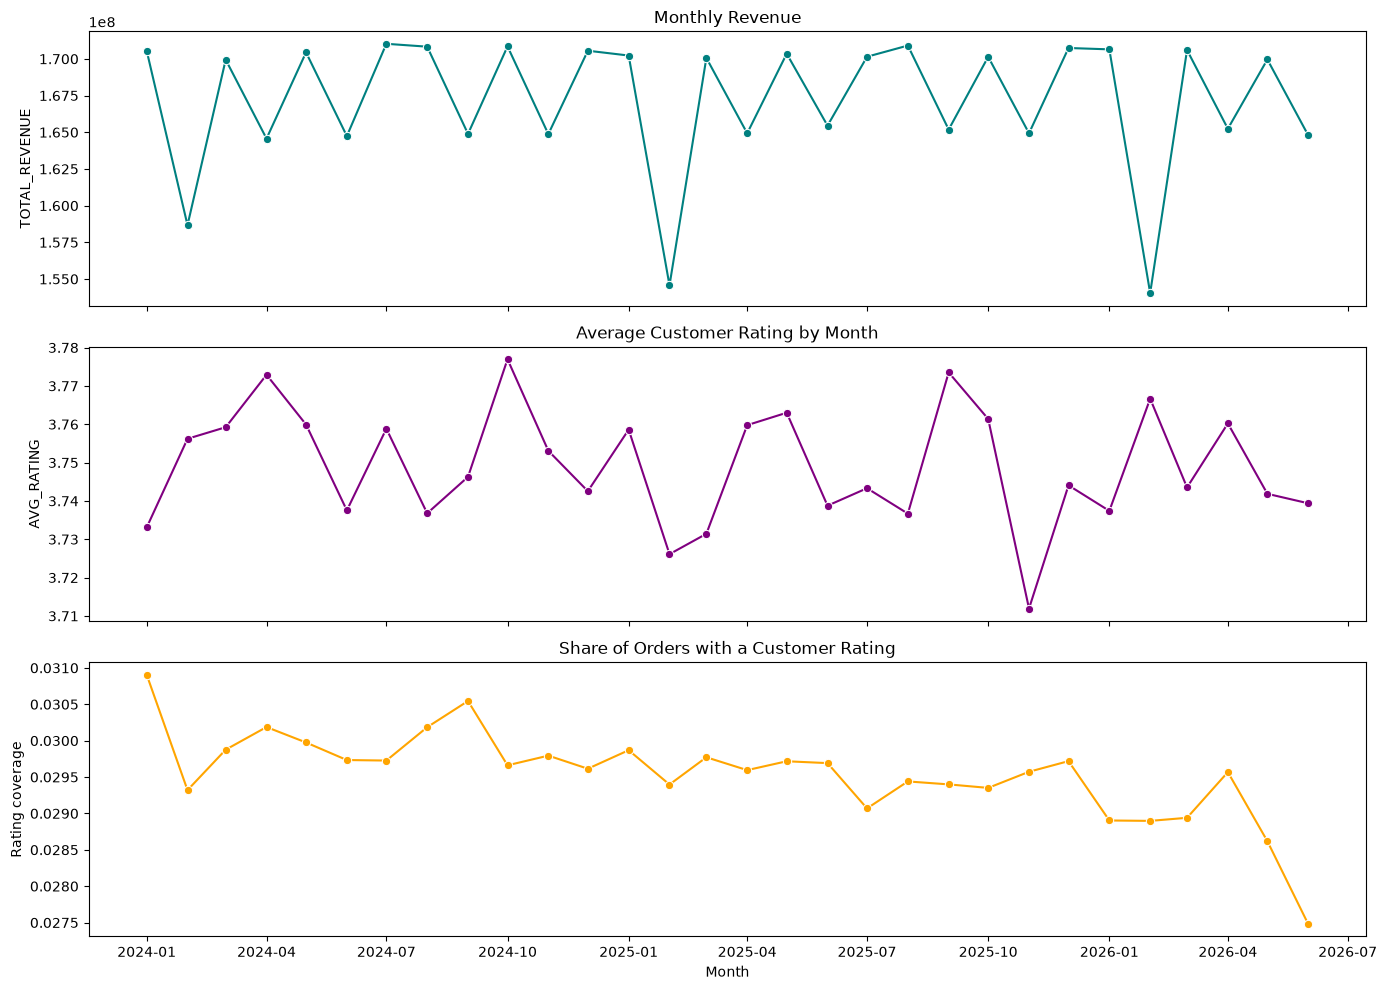

In [21]:
# lets perform the time-series analysis to check monthly revenue and ratings
dataframes['FACT_ORDERS']['ORDER_MONTH'] = dataframes['FACT_ORDERS']['ORDER_DATE'].dt.to_period('M')

monthly_ts = dataframes['FACT_ORDERS'].groupby('ORDER_MONTH').agg(
    TOTAL_ORDERS=('ORDER_ID', 'nunique'),
    TOTAL_REVENUE=('SALES_AMOUNT', 'sum'),
    AVG_RATING=('CUSTOMER_RATING', 'mean'),
    RATED_ORDERS=('CUSTOMER_RATING', 'count')
).reset_index()

monthly_ts['RATING_COVERAGE'] = (monthly_ts['RATED_ORDERS'] / monthly_ts['TOTAL_ORDERS'])
monthly_ts['ORDER_MONTH'] = monthly_ts['ORDER_MONTH'].dt.to_timestamp()

display(monthly_ts.head())
print(f"FACT_ORDERS rows: {len(dataframes['FACT_ORDERS']):,}")
print(f"Orders with missing rating: {dataframes['FACT_ORDERS']['CUSTOMER_RATING'].isna().sum():,}")

fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
sns.lineplot(data=monthly_ts, x='ORDER_MONTH', y='TOTAL_REVENUE', marker='o', ax=ax[0], color='teal')
ax[0].set_title('Monthly Revenue')

sns.lineplot(data=monthly_ts, x='ORDER_MONTH', y='AVG_RATING', marker='o', ax=ax[1], color='purple')
ax[1].set_title('Average Customer Rating by Month')

sns.lineplot(data=monthly_ts, x='ORDER_MONTH', y='RATING_COVERAGE', marker='o', ax=ax[2], color='orange')
ax[2].set_title('Share of Orders with a Customer Rating')
ax[2].set_ylabel('Rating coverage')
ax[2].set_xlabel('Month')

plt.tight_layout()
plt.show()

##### In the data model table, the orders has `10,000,000` data, where the Customer_Rating missing `9,704,459` which is only 3% of customer_rating of orders has avilable, so to build a model for predict the revenue based on the Customer Satisfaction is become too mini model, that's why we move forward to build a model which predict the revenue based on the Customer Orders Patten.

### Correlation of the Orders

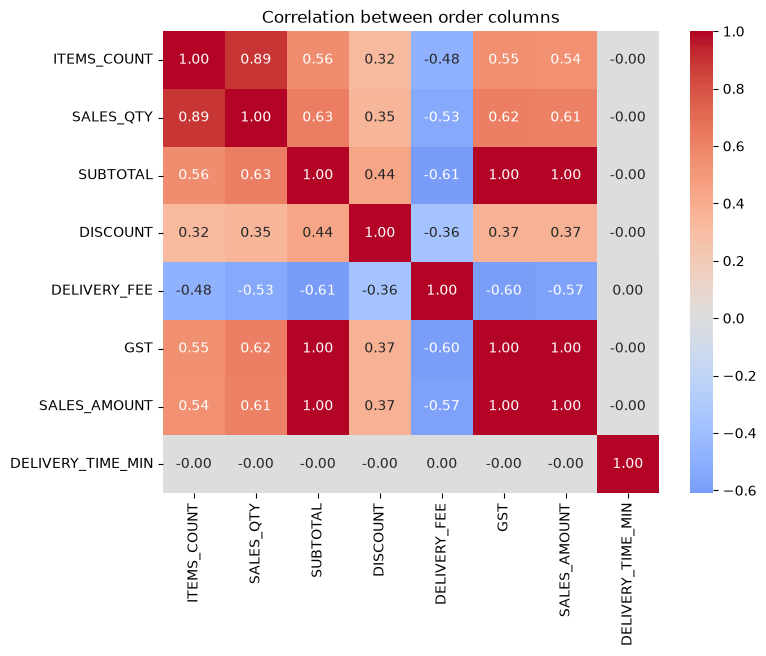

Correlation with SALES_AMOUNT:
GST                  1.00
SUBTOTAL             1.00
SALES_QTY            0.61
ITEMS_COUNT          0.54
DISCOUNT             0.36
DELIVERY_TIME_MIN   -0.00
DELIVERY_FEE        -0.57


In [22]:
numeric_cols = ["ITEMS_COUNT", "SALES_QTY", "SUBTOTAL", "DISCOUNT", "DELIVERY_FEE", "GST", "SALES_AMOUNT", "DELIVERY_TIME_MIN"]
corr = dataframes['FACT_ORDERS'][numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between order columns")
plt.show()

strong = corr["SALES_AMOUNT"].drop("SALES_AMOUNT").sort_values(ascending=False)
print("Correlation with SALES_AMOUNT:")
print(strong.round(3).to_string())

#### Insights:
- **`SUBTOTAL` and `SALES_AMOUNT` almost perfectly correlated** (close to 1), and `GST` too, because the total is built from them (see 4.3). This is a **warning, not a discovery**: using them to predict `SALES_AMOUNT` would be circular.
- Delivery time should show a correlation near 0 with everything. That matches its flat distribution.
- Use this chart to pick features that give *independent* information, not ones that are parts of the target.

In [23]:
ANALYSIS_YEAR = 2025
MONTH_ORDER = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Standardise Fact Orders
cols = ['ORDER_DATE', 'ORDER_ID', 'RESTAURANT_ID', 'CITY', 'SALES_AMOUNT', 'ORDER_MONTH']
fact_orders = dataframes['FACT_ORDERS'][cols].dropna(subset=cols).copy()
fact_orders['RESTAURANT_ID'] = fact_orders['RESTAURANT_ID'].astype(str)

# Build a clean Restaurant ID-to-Name Mapping
rest_dim = dataframes['DIM_RESTAURANTS'][['RESTAURANT_ID', 'RESTAURANT_NAME']].drop_duplicates('RESTAURANT_ID')
rest_map = dict(zip(rest_dim['RESTAURANT_ID'].astype(str), rest_dim['RESTAURANT_NAME']))

In [24]:
def process_pipeline(group_col, label_map=None):
    """Aggregates monthly data, isolates top 10 groups, fills gaps, and adds MoM metrics."""
    # Aggregation
    monthly = fact_orders.groupby([group_col, 'ORDER_MONTH']).agg(
        MONTHLY_ORDERS=('ORDER_ID', 'nunique'),
        MONTHLY_REVENUE=('SALES_AMOUNT', 'sum')
    ).reset_index()
    
    # Identify Top 10 by total orders in analysis year
    year_data = monthly[monthly['ORDER_MONTH'].dt.year == ANALYSIS_YEAR]
    top_groups = year_data.groupby(group_col)['MONTHLY_ORDERS'].sum().nlargest(10).index.tolist()
    
    # Complete missing entity-months with reindex
    all_months = pd.period_range(fact_orders['ORDER_MONTH'].min(), fact_orders['ORDER_MONTH'].max(), freq='M')
    idx = pd.MultiIndex.from_product([top_groups, all_months], names=[group_col, 'ORDER_MONTH'])
    
    df = (monthly[monthly[group_col].isin(top_groups)]
          .set_index([group_col, 'ORDER_MONTH'])
          .reindex(idx, fill_value=0)
          .reset_index()
          .sort_values([group_col, 'ORDER_MONTH']))
    
    # Add display names and Month categories
    df['LABEL'] = df[group_col].map(label_map) if label_map else df[group_col]
    df['LABEL'] = df['LABEL'].fillna(df[group_col])
    df['MONTH_NAME'] = pd.Categorical(df['ORDER_MONTH'].dt.strftime('%b'), categories=MONTH_ORDER, ordered=True)
    
    # Months have 28 to 31 days, so we also compare the revenue per day
    df['DAYS_IN_MONTH'] = df['ORDER_MONTH'].dt.days_in_month
    df['REVENUE_PER_DAY'] = df['MONTHLY_REVENUE'] / df['DAYS_IN_MONTH']
    
    # Month-over-Month changes (Calculated across the entire timeline to avoid boundary errors)
    grouped = df.groupby(group_col)
    for col in ['MONTHLY_ORDERS', 'MONTHLY_REVENUE', 'REVENUE_PER_DAY']:
        prev = grouped[col].shift(1)
        df[f'{col}_CHANGE'] = df[col] - prev
        df[f'{col}_CHANGE_PCT'] = ((df[col] / prev.replace(0, np.nan)) - 1) * 100
        
    # Return filtered data for the chosen analysis year
    df = df[df['ORDER_MONTH'].dt.year == ANALYSIS_YEAR]
    return df, top_groups


def plot_trends(df, group_col, top_groups, title):
    """Plots 2 subplots (Orders & Revenue) containing a 5x2 grid layout of entities."""
    for metric in ['MONTHLY_ORDERS', 'MONTHLY_REVENUE']:
        fig, axes = plt.subplots(5, 2, figsize=(14, 12), sharex=True)
        for i, group in enumerate(top_groups):
            ax = axes.flat[i]
            sub_df = df[df[group_col] == group]
            sns.lineplot(data=sub_df, x='MONTH_NAME', y=metric, marker='o', ax=ax)
            ax.set_title(sub_df['LABEL'].iloc[0])
            ax.set_xlabel('Month' if i >= 8 else '')
            
        fig.suptitle(f"{title} - {ANALYSIS_YEAR}: {metric.replace('_', ' ').title()}", fontsize=14, weight='bold')
        plt.tight_layout()
        plt.show()


def generate_pivot_table(df, index_cols):
    """Generates structured Root-Cause pivot tables."""
    metrics = ['MONTHLY_ORDERS', 'MONTHLY_ORDERS_CHANGE', 'MONTHLY_REVENUE', 'MONTHLY_REVENUE_CHANGE']
    pivot = df.pivot_table(index=index_cols, columns='MONTH_NAME', values=metrics, aggfunc='first')
    return pivot.reindex(columns=MONTH_ORDER, level=1)

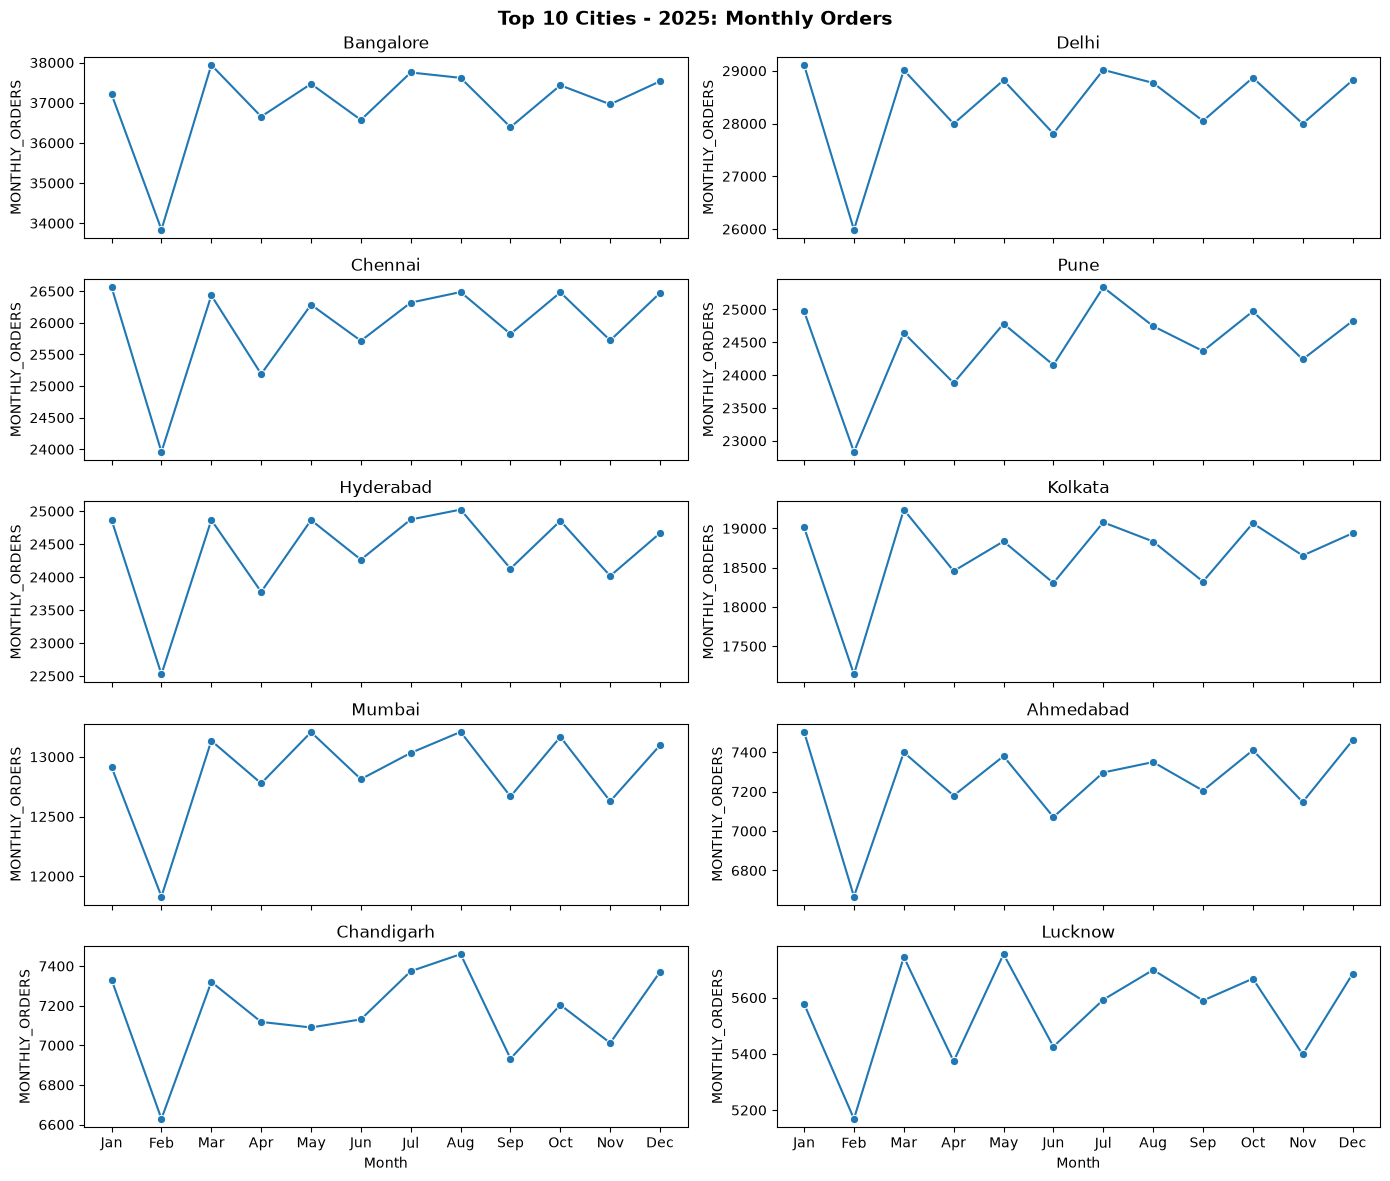

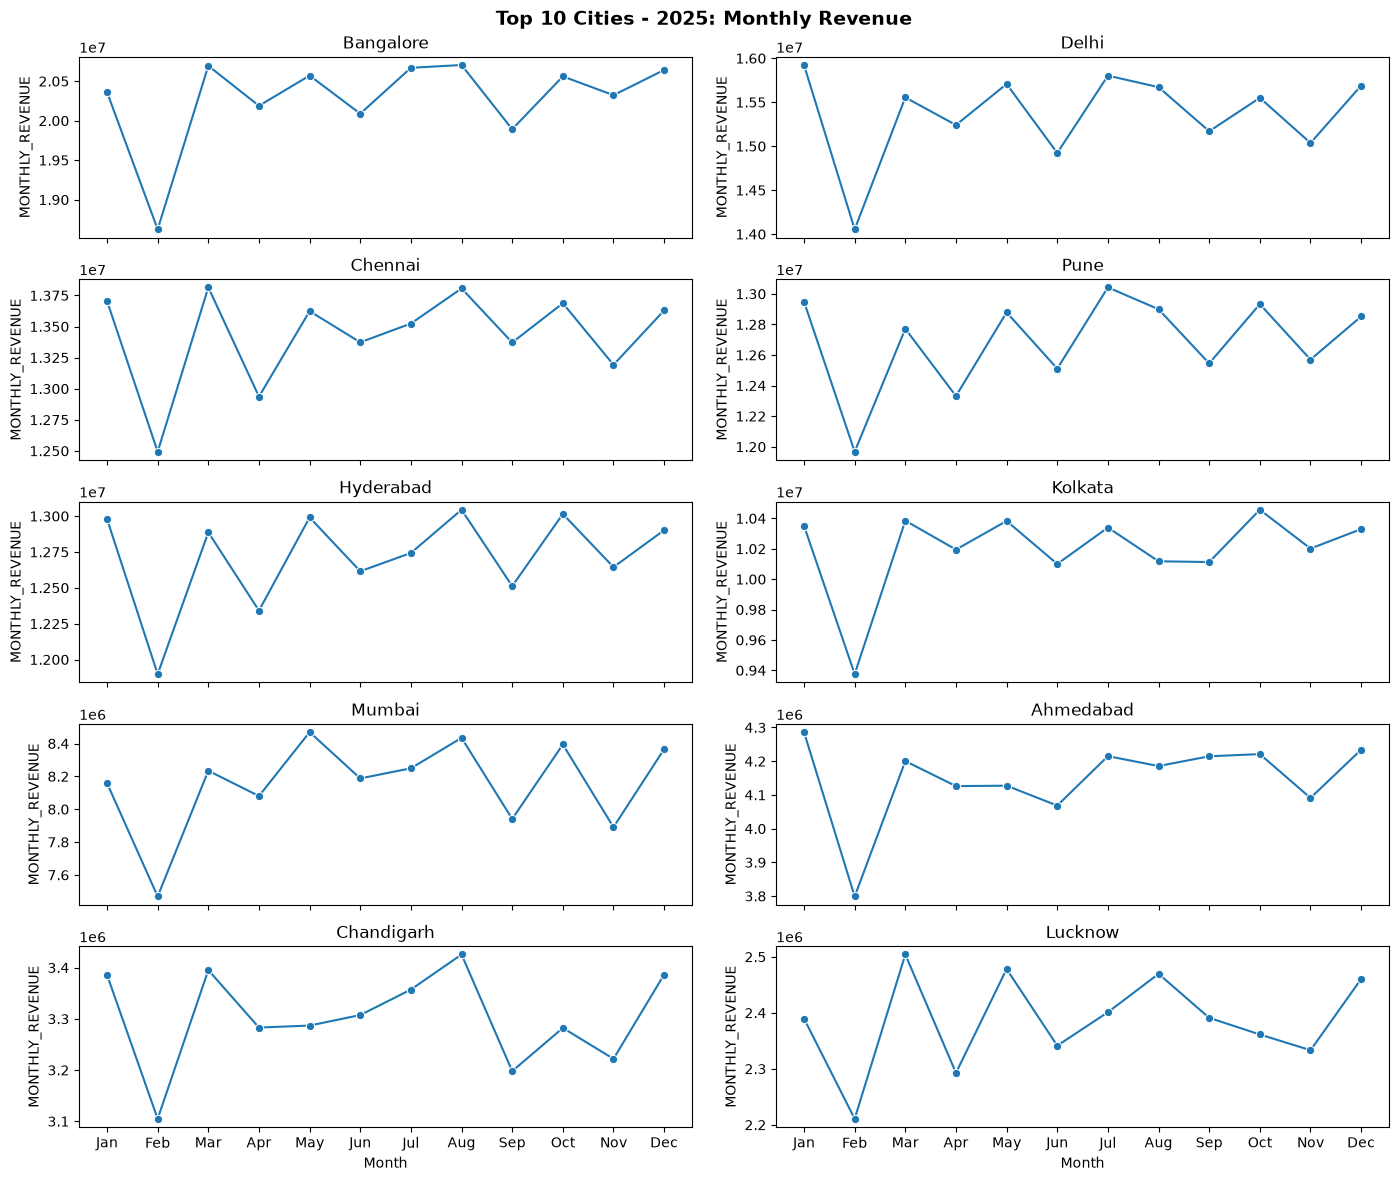

In [25]:
city_df, top_cities = process_pipeline('CITY')
plot_trends(city_df, 'CITY', top_cities, 'Top 10 Cities')

## 8. Root-cause analysis: what drives the revenue
##### the monthly table shows WHEN the revenue of a restaurant or a city moves (8.1), the next two parts show WHERE the revenue comes from: the customer occupation (8.2) and the city in every quarter (8.3).
##### 8.1 Monthly storytelling table (revenue per day change % for the top 10 restaurants and cities)

In [26]:
def generate_storytelling_pivot(df, index_cols):
    # 1. Rename columns to match the clean presentation layout
    rename_dict = {
        'MONTHLY_ORDERS': 'Orders',
        'MONTHLY_REVENUE': 'Revenue',
        'REVENUE_PER_DAY_CHANGE_PCT': 'Revenue Per Day Change %'
    }
    
    # 2. Pivot the data using specific metrics
    metrics = list(rename_dict.keys())
    pivot = df.pivot_table(index=index_cols, columns='MONTH_NAME', values=metrics, aggfunc='first')
    # 3. Restructure the MultiIndex so months are the top tier, and metrics are the sub-columns
    pivot = pivot.swaplevel(0, 1, axis=1)
    
    # 4. Enforce chronological month order and structural column order
    ordered_sub_cols = metrics
    nested_columns = [(m, c) for m in MONTH_ORDER for c in ordered_sub_cols]
    pivot = pivot.reindex(columns=nested_columns)
    pivot = pivot.rename(columns=rename_dict)
    
    styled_pivot = pivot.style.format(formatter={
        complex_col: "{:.1f}%" if "Change %" in complex_col[1] else "{:,.0f}" 
        for complex_col in pivot.columns
    }).background_gradient(
        cmap='RdYlGn', 
        subset=[c for c in pivot.columns if "Change %" in c[1]], 
        axis=1,
        vmin=-20, vmax=20
    )
    
    return styled_pivot

city_story_table = generate_storytelling_pivot(city_df, ['CITY'])
display(city_story_table)

##### 8.2 Revenue by customer occupation
##### the question is: does any customer group bring more revenue? The orders are first added up for every customer (100,000 rows instead of 10,000,000) and then the occupation of the customer is joined. `Revenue_Per_Customer` is the fair comparison, because the number of customers is different in every occupation.

Customers with orders but no row in DIM_CUSTOMER: 0
    OCCUPATION  Customers  Total_Orders   Total_Revenue  Revenue_Per_Customer  Revenue_Per_Order  Revenue_Share_%
       Student      53357       5337341 2,676,795,386.9              50,167.7              501.5             53.4
      Employee      30408       3040748 1,525,055,412.3              50,153.1              501.5             30.4
Self Employeed      13913       1389772   696,340,871.8              50,049.7              501.0             13.9
    House wife       2322        232139   116,663,709.4              50,242.8              502.6              2.3


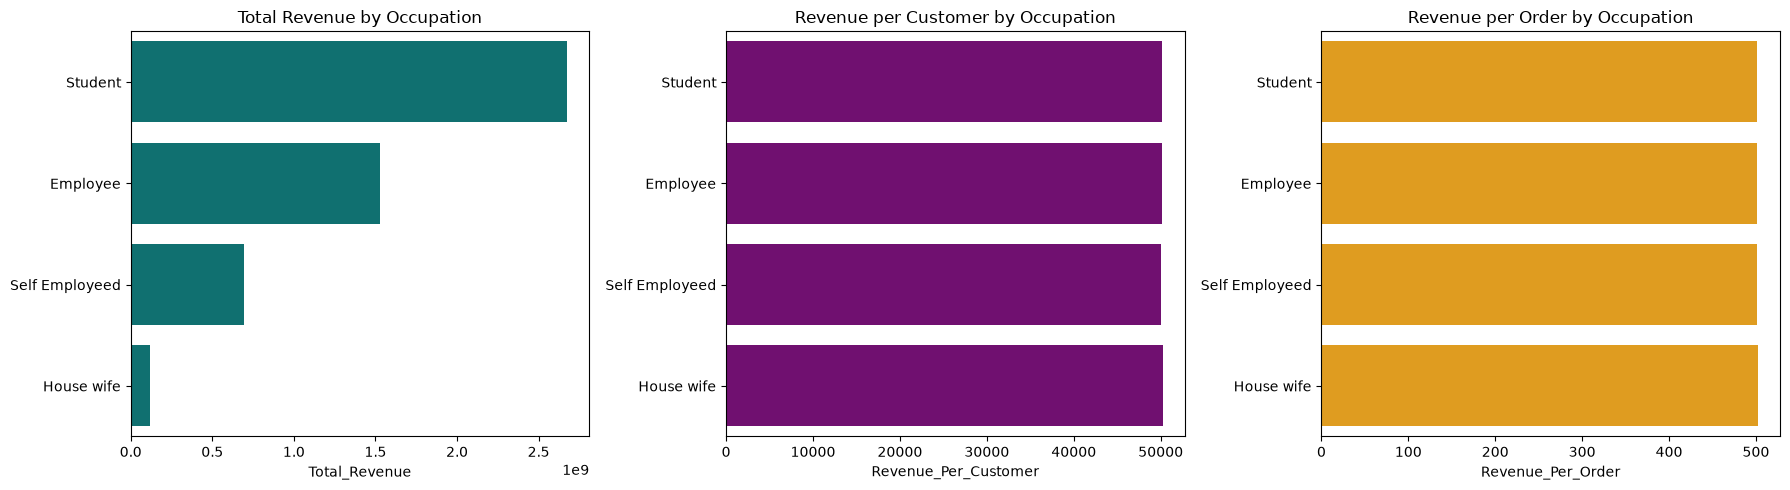

In [27]:
# lets check which customer occupation brings the revenue
# 1 add up the orders of every customer first (small table), then join the occupation
customer_revenue = dataframes['FACT_ORDERS'].groupby('CUSTOMER_ID').agg(
    Orders=('ORDER_ID', 'nunique'),
    Total_Revenue=('SALES_AMOUNT', 'sum')
).reset_index()
customer_revenue['CUSTOMER_ID'] = customer_revenue['CUSTOMER_ID'].astype(str)

customer_occupation = dataframes['DIM_CUSTOMER'][['CUSTOMER_ID', 'OCCUPATION']].drop_duplicates('CUSTOMER_ID').copy()
customer_occupation['CUSTOMER_ID'] = customer_occupation['CUSTOMER_ID'].astype(str)
customer_occupation['OCCUPATION'] = customer_occupation['OCCUPATION'].fillna('Unknown')

customer_revenue = customer_revenue.merge(customer_occupation, on='CUSTOMER_ID', how='left')
customer_revenue['OCCUPATION'] = customer_revenue['OCCUPATION'].fillna('Unknown')
print(f"Customers with orders but no row in DIM_CUSTOMER: {(customer_revenue['OCCUPATION'] == 'Unknown').sum():,}")

# 2 one row for every occupation
occupation_revenue = customer_revenue.groupby('OCCUPATION').agg(
    Customers=('CUSTOMER_ID', 'nunique'),
    Total_Orders=('Orders', 'sum'),
    Total_Revenue=('Total_Revenue', 'sum')
).reset_index()
occupation_revenue['Revenue_Per_Customer'] = occupation_revenue['Total_Revenue'] / occupation_revenue['Customers']
occupation_revenue['Revenue_Per_Order'] = occupation_revenue['Total_Revenue'] / occupation_revenue['Total_Orders']
occupation_revenue['Revenue_Share_%'] = occupation_revenue['Total_Revenue'] / occupation_revenue['Total_Revenue'].sum() * 100
occupation_revenue = occupation_revenue.sort_values('Total_Revenue', ascending=False).reset_index(drop=True)
print(occupation_revenue.to_string(index=False, float_format=lambda value: f'{value:,.1f}'))

# 3 plot: total revenue, revenue per customer and revenue per order of every occupation
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=occupation_revenue, y='OCCUPATION', x='Total_Revenue', ax=ax[0], color='teal')
ax[0].set_title('Total Revenue by Occupation')
sns.barplot(data=occupation_revenue, y='OCCUPATION', x='Revenue_Per_Customer', ax=ax[1], color='purple')
ax[1].set_title('Revenue per Customer by Occupation')
sns.barplot(data=occupation_revenue, y='OCCUPATION', x='Revenue_Per_Order', ax=ax[2], color='orange')
ax[2].set_title('Revenue per Order by Occupation')
for axis in ax:
    axis.set_ylabel('')
plt.tight_layout()
plt.show()

#### Insights:
##### if the bars of `Revenue_Per_Customer` and `Revenue_Per_Order` are almost equal for all occupations, the occupation is not a driver of revenue (the total only differs because the number of customers differs). Only the occupation was plotted, other columns of `DIM_CUSTOMER` (`AGE_SEGMENT`, `GENDER`, `MARITAL_STATUS`, `EDUCATION`) can be checked by changing the column in the `groupby`. *(the insight note is written after you run this cell)*

##### 8.3 City revenue by quarter
##### the top 10 cities by total revenue, added up for every calendar quarter. This is the same view the model will predict, so the quarter-to-quarter movement of a city is visible before the modelling.

ORDER_QUARTER  2024Q1  2024Q2  2024Q3  2024Q4  2025Q1  2025Q2  2025Q3  2025Q4  2026Q1  2026Q2
CITY                                                                                         
Bangalore       60.43   60.48   61.75   61.21   59.68   60.85   61.27   61.53   60.31   60.58
Delhi           46.02   45.97   46.70   46.53   45.53   45.87   46.64   46.27   45.65   46.00
Chennai         40.28   40.43   40.35   40.63   40.01   39.93   40.70   40.51   39.88   40.18
Hyderabad       37.80   37.60   38.73   38.29   37.77   37.95   38.30   38.56   37.57   38.00
Pune            37.93   38.12   38.43   38.29   37.69   37.72   38.49   38.35   37.29   37.83
Kolkata         30.87   30.24   30.99   30.81   30.11   30.68   30.57   30.99   30.45   30.43
Mumbai          24.06   24.22   24.39   24.90   23.86   24.74   24.62   24.65   24.21   24.56
Ahmedabad       12.37   12.59   12.72   12.60   12.29   12.32   12.62   12.55   12.31   12.27
Chandigarh       9.74    9.88   10.05    9.91    9.89    9.8

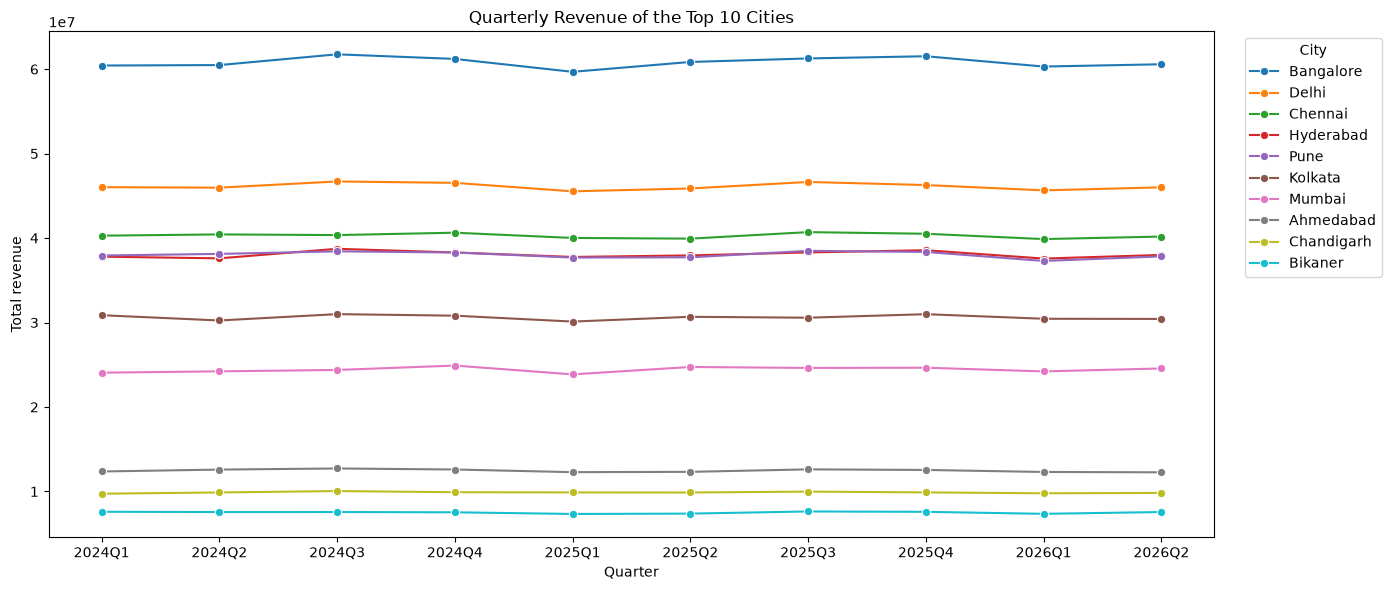

In [28]:
# lets plot the revenue of the top 10 cities for every quarter
mart_city_quarter = dataframes['MART_DAILY_CITY_REVENUE'].copy()
mart_city_quarter['ORDER_QUARTER'] = mart_city_quarter['ORDER_DATE'].dt.to_period('Q')

city_quarter_revenue = mart_city_quarter.groupby(['CITY', 'ORDER_QUARTER']).agg(
    Total_Orders=('ORDERS', 'sum'),
    Total_Revenue=('GMV', 'sum')
).reset_index()

TOP_N_CITIES = 10
top_revenue_cities = city_quarter_revenue.groupby('CITY')['Total_Revenue'].sum().nlargest(TOP_N_CITIES).index.tolist()
top_city_quarter = city_quarter_revenue[city_quarter_revenue['CITY'].isin(top_revenue_cities)].copy()
top_city_quarter['ORDER_QUARTER'] = top_city_quarter['ORDER_QUARTER'].astype(str)

# table: one row for every city, one column for every quarter
city_quarter_table = top_city_quarter.pivot(index='CITY', columns='ORDER_QUARTER', values='Total_Revenue').reindex(top_revenue_cities)
print((city_quarter_table / 1_000_000).to_string(float_format=lambda value: f'{value:,.2f}'))
print("(revenue in millions)")

# plot: revenue of the top 10 cities in every quarter
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=top_city_quarter, x='ORDER_QUARTER', y='Total_Revenue', hue='CITY', hue_order=top_revenue_cities, marker='o', ax=ax)
ax.set_title('Quarterly Revenue of the Top 10 Cities')
ax.set_xlabel('Quarter')
ax.set_ylabel('Total revenue')
ax.legend(title='City', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### a quarter has 90 to 92 days, so a small difference between two quarters can come only from the number of days (the model uses revenue per day for this reason). The first and the last quarter must be complete, check the last quarter in the next sections. *(the insight note is written after you run this cell)*

## 9. Cleaning decision

| Problem found | Decision | Why |
|---|---|---|
| One restaurant `COST` of 300,350 (median 250) | Cap `COST` at the 99.9th percentile | One wrong value would distort any average |
| 2,132 cuisine labels, same mix in different order | Sort the words (`CUISINE_SORTED`, section 6.2) | Stops one cuisine being split in two |
| 97% of ratings missing | Do not use ratings as model inputs | Too sparse, and only known after delivery |
| Discount capped at 150, delivery fee has 5 values | Keep as they are | They are real rules, not errors |
| Very large orders (up to 28,885) | Keep | They are real revenue |
| `SALES_AMOUNT` = `SUBTOTAL` - `DISCOUNT` + `DELIVERY_FEE` + `GST` exactly | Do not use these columns of the same quarter as features | The model would only do arithmetic (leakage) |
| Cancellations are not in the data | Predict revenue of delivered orders only | Nothing else is available |
| Days or quarters with no orders are missing from the city-day mart | Fill with 0 in section 10 | Otherwise the model never sees quiet periods |

In [29]:
# lets cap the wrong COST value of the restaurants
MAX_COST_QUANTILE = 0.999
cost_cap = dataframes['DIM_RESTAURANTS']['COST'].quantile(MAX_COST_QUANTILE)
print(f"COST before: max = {dataframes['DIM_RESTAURANTS']['COST'].max():,.0f} | cap (99.9th percentile) = {cost_cap:,.0f}")
dataframes['DIM_RESTAURANTS']['COST'] = dataframes['DIM_RESTAURANTS']['COST'].clip(upper=cost_cap)
print(f"COST after : max = {dataframes['DIM_RESTAURANTS']['COST'].max():,.0f}, median = {dataframes['DIM_RESTAURANTS']['COST'].median():,.0f}, mean = {dataframes['DIM_RESTAURANTS']['COST'].mean():,.1f}")

COST before: max = 300,350 | cap (99.9th percentile) = 1,600
COST after : max = 1,600, median = 250, mean = 285.0


##### `COST` is not a feature of the quarterly city model, the cap is a data-cleaning step for any later restaurant analysis. If you rerun the notebook, run this cell only once (running it again only cuts the already capped values at the same level, so nothing breaks). The cuisine fix is already done in section 6.2.

## 10. Feature engineering : City Revenue on Quarterly Basis
##### the first idea was to predict the revenue of every city for every day, but the daily revenue of a city is too noisy (the median city-day has only 4 orders). So we predict the revenue of every city for the next quarter (3 months), where the ups and downs of single days are added up and the noise becomes small.

| Orders per day of a city | Smallest possible error on 1 day | Smallest possible error on 1 quarter |
|---|---|---|
| 1 | 1.01 | 0.113 |
| 4 | 0.53 | 0.057 |
| 10 | 0.34 | 0.036 |
| 28 | 0.20 | 0.021 |
| 100 | 0.11 | 0.011 |

##### the table is my own calculation (not an output of this notebook): it uses the mean 501 and the standard deviation 453 of `SALES_AMOUNT` and assumes the orders arrive at random. Even a perfect model cannot go below these errors (WMAPE), because the random ups and downs cannot be predicted. Adding 91 days together makes the error about 9 times smaller.

##### the steps: 10.1 quarterly revenue table, 10.2 customer order pattern, 10.3 features from the previous quarters, 10.4 feature check, 10.5 correlation, 10.6 feature dictionary.
##### 10.1 Quarterly revenue table

In [30]:
# lets build the quarterly revenue table of every city from the daily city mart
# 1 mark the quarter of every day (calendar quarters: Jan-Mar, Apr-Jun, Jul-Sep, Oct-Dec)
dataframes['MART_DAILY_CITY_REVENUE']['ORDER_QUARTER'] = dataframes['MART_DAILY_CITY_REVENUE']['ORDER_DATE'].dt.to_period('Q')

# 2 add up all the days of every quarter for every city
quarterly_city_revenue = dataframes['MART_DAILY_CITY_REVENUE'].groupby(['CITY', 'ORDER_QUARTER']).agg(
    QUARTERLY_ORDERS=('ORDERS', 'sum'),
    QUARTERLY_REVENUE=('GMV', 'sum')
).reset_index()

# 3 check that the last quarter is complete (every day of the quarter is in the data)
LAST_QUARTER = quarterly_city_revenue['ORDER_QUARTER'].max()
FORECAST_QUARTER = LAST_QUARTER + 1
last_quarter_days = dataframes['MART_DAILY_CITY_REVENUE'][dataframes['MART_DAILY_CITY_REVENUE']['ORDER_QUARTER'] == LAST_QUARTER]['ORDER_DATE'].nunique()
last_quarter_expected_days = (LAST_QUARTER.end_time.normalize() - LAST_QUARTER.start_time).days + 1
print(f"Last quarter {LAST_QUARTER}: {last_quarter_days} days in the data, {last_quarter_expected_days} days expected")

# 4 complete the missing city-quarters with reindex, one more quarter is added at the end
# this extra quarter is the quarter we want to predict, so its revenue stays empty
all_quarters = pd.period_range(quarterly_city_revenue['ORDER_QUARTER'].min(), FORECAST_QUARTER, freq='Q')
all_cities = sorted(quarterly_city_revenue['CITY'].unique())
idx = pd.MultiIndex.from_product([all_cities, all_quarters], names=['CITY', 'ORDER_QUARTER'])
quarterly_city_revenue = (quarterly_city_revenue
                          .set_index(['CITY', 'ORDER_QUARTER'])
                          .reindex(idx)
                          .reset_index())

# a known quarter without any order has 0 revenue
is_known_quarter = quarterly_city_revenue['ORDER_QUARTER'] <= LAST_QUARTER
for column in ['QUARTERLY_ORDERS', 'QUARTERLY_REVENUE']:
    quarterly_city_revenue.loc[is_known_quarter & quarterly_city_revenue[column].isna(), column] = 0

# 5 every city starts from the quarter of its first order
first_active_quarter = (quarterly_city_revenue[quarterly_city_revenue['QUARTERLY_REVENUE'] > 0]
                        .groupby('CITY')['ORDER_QUARTER'].min().reset_index(name='FIRST_ACTIVE_QUARTER'))
quarterly_city_revenue = quarterly_city_revenue.merge(first_active_quarter, on='CITY')
quarterly_city_revenue = quarterly_city_revenue[quarterly_city_revenue['ORDER_QUARTER'] >= quarterly_city_revenue['FIRST_ACTIVE_QUARTER']]
quarterly_city_revenue = quarterly_city_revenue.drop(columns='FIRST_ACTIVE_QUARTER').reset_index(drop=True)

# 6 quarters have 90 to 92 days, so we use the revenue per day (the days are multiplied back at the end)
quarter_start = quarterly_city_revenue['ORDER_QUARTER'].dt.start_time
quarter_end = quarterly_city_revenue['ORDER_QUARTER'].dt.end_time.dt.normalize()
quarterly_city_revenue['DAYS_IN_QUARTER'] = (quarter_end - quarter_start).dt.days + 1
quarterly_city_revenue['REVENUE_PER_DAY'] = quarterly_city_revenue['QUARTERLY_REVENUE'] / quarterly_city_revenue['DAYS_IN_QUARTER']
quarterly_city_revenue['AOV'] = quarterly_city_revenue['QUARTERLY_REVENUE'] / quarterly_city_revenue['QUARTERLY_ORDERS'].replace(0, np.nan)

print(f"Quarterly table: {quarterly_city_revenue.shape} | cities: {quarterly_city_revenue['CITY'].nunique()}")
print(f"Quarters: {quarterly_city_revenue['ORDER_QUARTER'].min()} to {LAST_QUARTER} (predict: {FORECAST_QUARTER})")

# national revenue of every quarter
national_quarterly_revenue = quarterly_city_revenue[quarterly_city_revenue['ORDER_QUARTER'] <= LAST_QUARTER].groupby('ORDER_QUARTER').agg(
    Total_Orders=('QUARTERLY_ORDERS', 'sum'),
    Total_Revenue=('QUARTERLY_REVENUE', 'sum'),
    Days=('DAYS_IN_QUARTER', 'first')
).reset_index()
national_quarterly_revenue['Revenue_Per_Day'] = national_quarterly_revenue['Total_Revenue'] / national_quarterly_revenue['Days']
print(national_quarterly_revenue.to_string(index=False))

Last quarter 2026Q2: 91 days in the data, 91 days expected
Quarterly table: (6072, 7) | cities: 552
Quarters: 2024Q1 to 2026Q2 (predict: 2026Q3)
ORDER_QUARTER  Total_Orders  Total_Revenue  Days  Revenue_Per_Day
       2024Q1    996,542.00 499,164,602.76    91     5,485,325.31
       2024Q2    997,323.00 499,746,898.80    91     5,491,724.16
       2024Q3  1,009,803.00 506,746,397.06    92     5,508,113.01
       2024Q4  1,009,504.00 506,279,146.50    92     5,503,034.20
       2025Q1    987,148.00 494,860,910.64    90     5,498,454.56
       2025Q2    997,728.00 500,729,776.98    91     5,502,525.02
       2025Q3  1,009,602.00 506,237,214.74    92     5,502,578.42
       2025Q4  1,008,683.00 505,810,444.42    92     5,497,939.61
       2026Q1    986,958.00 495,287,895.17    90     5,503,198.84
       2026Q2    996,709.00 499,992,093.32    91     5,494,418.61


##### one row for every city and every quarter, plus one empty row per city for the quarter we want to predict (`FORECAST_QUARTER`). The quarters are calendar quarters (Jan-Mar, Apr-Jun, Jul-Sep, Oct-Dec). If you use the financial year names (Q1 = Apr-Jun) only the names change, the 3 month blocks are the same.
##### check the printed line of the last quarter: the days in the data must be equal to the days expected. If the last quarter is incomplete, the model learns a wrong low revenue (in the daily chart of the earlier model the last days of June 2026 were lower than normal, so this check matters).

##### 10.2 Customer order pattern of every city in every quarter

In [31]:
# lets collect the customer order pattern of every city in every quarter from FACT_ORDERS
dataframes['FACT_ORDERS']['ORDER_QUARTER'] = dataframes['FACT_ORDERS']['ORDER_DATE'].dt.to_period('Q')
dataframes['FACT_ORDERS']['IS_UPI'] = (dataframes['FACT_ORDERS']['PAYMENT_METHOD'] == 'UPI').astype(int)

quarterly_order_pattern = dataframes['FACT_ORDERS'].groupby(['CITY', 'ORDER_QUARTER']).agg(
    UNIQUE_CUSTOMERS=('CUSTOMER_ID', 'nunique'),
    AVG_ITEMS_PER_ORDER=('ITEMS_COUNT', 'mean'),
    TOTAL_DISCOUNT=('DISCOUNT', 'sum'),
    TOTAL_SUBTOTAL=('SUBTOTAL', 'sum'),
    UPI_SHARE=('IS_UPI', 'mean')
).reset_index()
quarterly_order_pattern['DISCOUNT_SHARE'] = quarterly_order_pattern['TOTAL_DISCOUNT'] / quarterly_order_pattern['TOTAL_SUBTOTAL']
quarterly_order_pattern = quarterly_order_pattern.drop(columns=['TOTAL_DISCOUNT', 'TOTAL_SUBTOTAL'])

quarterly_city_revenue = quarterly_city_revenue.merge(quarterly_order_pattern, on=['CITY', 'ORDER_QUARTER'], how='left')
quarterly_city_revenue['CUSTOMERS_PER_ORDER'] = quarterly_city_revenue['UNIQUE_CUSTOMERS'] / quarterly_city_revenue['QUARTERLY_ORDERS'].replace(0, np.nan)

print(quarterly_city_revenue[quarterly_city_revenue['CITY'] == quarterly_city_revenue.groupby('CITY')['QUARTERLY_REVENUE'].sum().idxmax()].to_string(index=False))

     CITY ORDER_QUARTER  QUARTERLY_ORDERS  QUARTERLY_REVENUE  DAYS_IN_QUARTER  REVENUE_PER_DAY    AOV  UNIQUE_CUSTOMERS  AVG_ITEMS_PER_ORDER  UPI_SHARE  DISCOUNT_SHARE  CUSTOMERS_PER_ORDER
Bangalore        2024Q1        110,057.00      60,426,107.88               91       664,023.16 549.04         66,953.00                 2.30       0.55            0.05                 0.61
Bangalore        2024Q2        110,308.00      60,479,436.05               91       664,609.19 548.28         66,735.00                 2.30       0.55            0.05                 0.60
Bangalore        2024Q3        111,599.00      61,753,341.64               92       671,231.97 553.35         67,249.00                 2.30       0.55            0.05                 0.60
Bangalore        2024Q4        111,549.00      61,206,962.54               92       665,293.07 548.70         67,461.00                 2.30       0.55            0.05                 0.60
Bangalore        2025Q1        108,991.00      59,680,4

##### these are the customer order pattern features of every city in every quarter (unique customers, items per order, discount share and UPI share). The idea is tested again on quarterly level, because on daily level these features had almost no importance.

##### 10.3 Features from the previous quarters and the target

In [32]:
# lets create the features from the previous quarters only (the revenue of a quarter is never used to predict itself)
quarterly_city_revenue = quarterly_city_revenue.sort_values(['CITY', 'ORDER_QUARTER']).reset_index(drop=True)
grouped_by_city = quarterly_city_revenue.groupby('CITY')

# 1 the last quarter and the quarter before it
for column in ['REVENUE_PER_DAY', 'AOV', 'CUSTOMERS_PER_ORDER', 'AVG_ITEMS_PER_ORDER', 'DISCOUNT_SHARE', 'UPI_SHARE']:
    quarterly_city_revenue[f'PREV_1Q_{column}'] = grouped_by_city[column].shift(1)
quarterly_city_revenue['PREV_2Q_REVENUE_PER_DAY'] = grouped_by_city['REVENUE_PER_DAY'].shift(2)

# 2 average revenue per day of ALL the previous quarters of the city
quarterly_city_revenue['QUARTERS_OF_HISTORY'] = grouped_by_city.cumcount()
quarterly_city_revenue['CUMULATIVE_REVENUE_PER_DAY'] = grouped_by_city['REVENUE_PER_DAY'].cumsum()
previous_total = quarterly_city_revenue.groupby('CITY')['CUMULATIVE_REVENUE_PER_DAY'].shift(1)
quarterly_city_revenue['PREV_AVG_REVENUE_PER_DAY'] = previous_total / quarterly_city_revenue['QUARTERS_OF_HISTORY'].replace(0, np.nan)

# 3 features which do not depend on the size of the city, so small and big cities can learn together
quarterly_city_revenue['LAST_QUARTER_VS_HISTORY'] = quarterly_city_revenue['PREV_1Q_REVENUE_PER_DAY'] / quarterly_city_revenue['PREV_AVG_REVENUE_PER_DAY']
quarterly_city_revenue['LAST_2_QUARTER_CHANGE'] = quarterly_city_revenue['PREV_1Q_REVENUE_PER_DAY'] / quarterly_city_revenue['PREV_2Q_REVENUE_PER_DAY']
quarterly_city_revenue['CITY_SIZE_LOG'] = np.log1p(quarterly_city_revenue['PREV_AVG_REVENUE_PER_DAY'])
quarterly_city_revenue['QUARTER_NUMBER'] = quarterly_city_revenue['ORDER_QUARTER'].dt.quarter
quarterly_city_revenue = quarterly_city_revenue.replace([np.inf, -np.inf], np.nan)

# 4 the target: how much the revenue per day of the quarter is higher or lower than the average of the previous quarters
# 1.0 means the city stays at its own average, 1.1 means 10% higher
quarterly_city_revenue['REVENUE_GROWTH_RATIO'] = quarterly_city_revenue['REVENUE_PER_DAY'] / quarterly_city_revenue['PREV_AVG_REVENUE_PER_DAY']
# the revenue of the quarter if the city stays at its own average
quarterly_city_revenue['BASE_QUARTER_REVENUE'] = quarterly_city_revenue['PREV_AVG_REVENUE_PER_DAY'] * quarterly_city_revenue['DAYS_IN_QUARTER']

FEATURE_COLUMNS = [
    'LAST_QUARTER_VS_HISTORY', 'LAST_2_QUARTER_CHANGE', 'CITY_SIZE_LOG', 'QUARTERS_OF_HISTORY', 'QUARTER_NUMBER',
    'PREV_1Q_AOV', 'PREV_1Q_CUSTOMERS_PER_ORDER', 'PREV_1Q_AVG_ITEMS_PER_ORDER', 'PREV_1Q_DISCOUNT_SHARE', 'PREV_1Q_UPI_SHARE'
]

# rows for the model: known revenue, at least 2 quarters of history and a city average above 0
has_history = (quarterly_city_revenue['QUARTERS_OF_HISTORY'] >= 2) & (quarterly_city_revenue['PREV_AVG_REVENUE_PER_DAY'] > 0)
model_data = quarterly_city_revenue[has_history & (quarterly_city_revenue['ORDER_QUARTER'] <= LAST_QUARTER)].copy()
forecast_data = quarterly_city_revenue[has_history & (quarterly_city_revenue['ORDER_QUARTER'] == FORECAST_QUARTER)].copy()

print(f"Rows for the model: {len(model_data):,} | cities to predict for {FORECAST_QUARTER}: {len(forecast_data):,}")
print(f"Number of features: {len(FEATURE_COLUMNS)}")
print(model_data.groupby('ORDER_QUARTER').size().to_string())

Rows for the model: 4,416 | cities to predict for 2026Q3: 552
Number of features: 10
ORDER_QUARTER
2024Q3    552
2024Q4    552
2025Q1    552
2025Q2    552
2025Q3    552
2025Q4    552
2026Q1    552
2026Q2    552
Freq: Q-DEC


##### every feature of a quarter is created from the quarters before it, so the model never sees the revenue it has to predict. `LAST_QUARTER_VS_HISTORY` tells if the last quarter was above or below the city's own average, `CITY_SIZE_LOG` tells the size of the city.
##### two simple baselines have to be beaten: `Last quarter` and `Average of all past quarters`.

##### 10.4 Feature check

                             Missing_Share_%     Min  Median       Max
LAST_QUARTER_VS_HISTORY                0.000   0.093   1.001     2.572
LAST_2_QUARTER_CHANGE                  0.000   0.095   1.000    13.292
CITY_SIZE_LOG                          0.000   1.415   7.223    13.410
QUARTERS_OF_HISTORY                    0.000   2.000   5.500     9.000
QUARTER_NUMBER                         0.000   1.000   2.500     4.000
PREV_1Q_AOV                            0.000 104.735 406.042 1,216.810
PREV_1Q_CUSTOMERS_PER_ORDER            0.000   0.603   1.000     1.000
PREV_1Q_AVG_ITEMS_PER_ORDER            0.000   1.000   2.299     6.000
PREV_1Q_DISCOUNT_SHARE                 0.000   0.000   0.057     0.200
PREV_1Q_UPI_SHARE                      0.000   0.000   0.550     1.000
Leakage check for Bangalore: largest gap between PREV_1Q_REVENUE_PER_DAY and the real previous quarter = 0.000000
REVENUE_GROWTH_RATIO of the model rows:
count   4,416.000
mean        1.006
std         0.138
min        

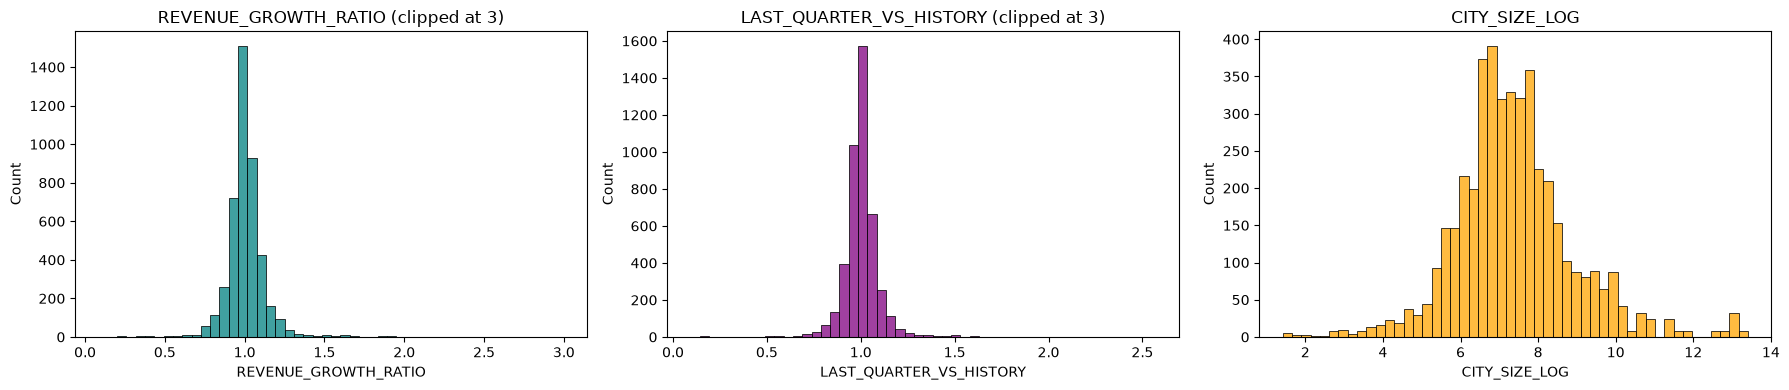

In [33]:
# lets check the features before the model uses them
# 1 missing values of every feature in the model rows
feature_check = pd.DataFrame({
    'Missing_Share_%': model_data[FEATURE_COLUMNS].isna().mean() * 100,
    'Min': model_data[FEATURE_COLUMNS].min(),
    'Median': model_data[FEATURE_COLUMNS].median(),
    'Max': model_data[FEATURE_COLUMNS].max()
})
print(feature_check.to_string(float_format=lambda value: f'{value:,.3f}'))

# 2 no leakage: the previous-quarter revenue of a row must be the revenue of the row before it
sample_city = model_data.groupby('CITY')['QUARTERLY_REVENUE'].sum().idxmax()
sample_rows = quarterly_city_revenue[quarterly_city_revenue['CITY'] == sample_city].reset_index(drop=True)
shift_gap = (sample_rows['PREV_1Q_REVENUE_PER_DAY'].iloc[1:].values - sample_rows['REVENUE_PER_DAY'].iloc[:-1].values)
print(f"Leakage check for {sample_city}: largest gap between PREV_1Q_REVENUE_PER_DAY and the real previous quarter = {np.nanmax(np.abs(shift_gap)):.6f}")

# 3 the target should be centred near 1.0
print("REVENUE_GROWTH_RATIO of the model rows:")
print(model_data['REVENUE_GROWTH_RATIO'].describe().to_string(float_format=lambda value: f'{value:,.3f}'))

# 4 distribution plot of the target and the main features
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(model_data['REVENUE_GROWTH_RATIO'].clip(0, 3), bins=50, ax=ax[0], color='teal')
ax[0].set_title('REVENUE_GROWTH_RATIO (clipped at 3)')
sns.histplot(model_data['LAST_QUARTER_VS_HISTORY'].clip(0, 3), bins=50, ax=ax[1], color='purple')
ax[1].set_title('LAST_QUARTER_VS_HISTORY (clipped at 3)')
sns.histplot(model_data['CITY_SIZE_LOG'], bins=50, ax=ax[2], color='orange')
ax[2].set_title('CITY_SIZE_LOG')
plt.tight_layout()
plt.show()

##### 10.5 Correlation of the features with the target

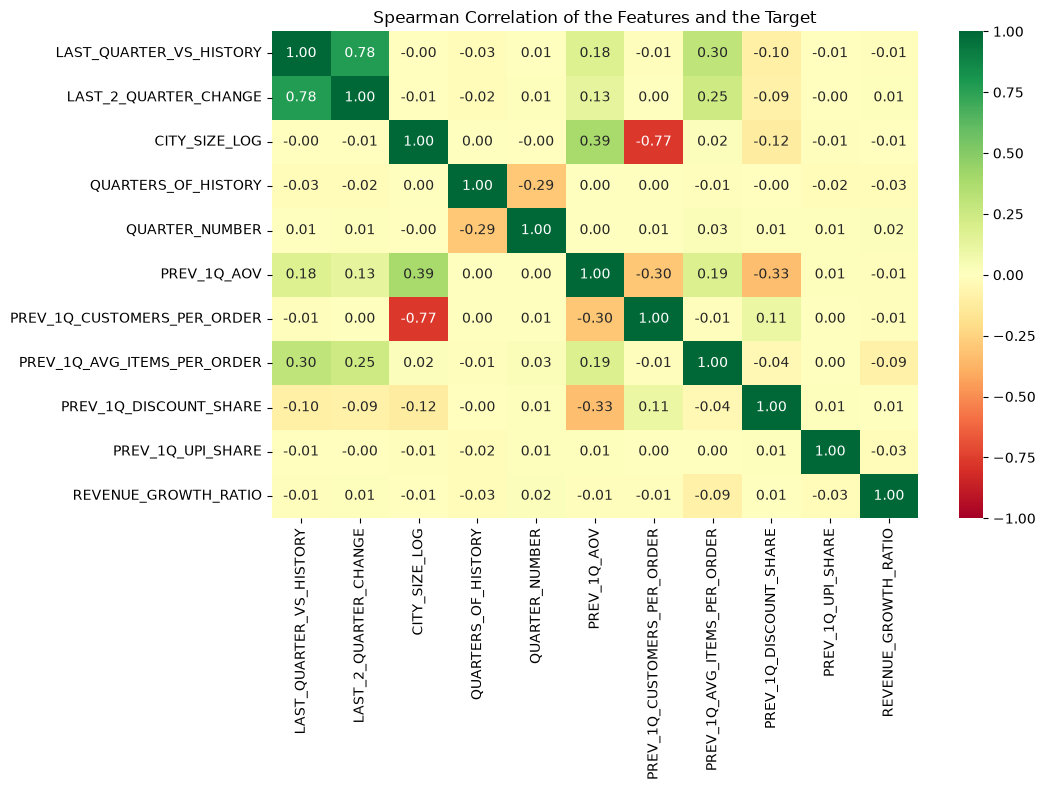

Correlation with REVENUE_GROWTH_RATIO:
PREV_1Q_AVG_ITEMS_PER_ORDER   -0.088
PREV_1Q_UPI_SHARE             -0.027
QUARTERS_OF_HISTORY           -0.026
QUARTER_NUMBER                 0.017
PREV_1Q_CUSTOMERS_PER_ORDER   -0.015
LAST_QUARTER_VS_HISTORY       -0.014
PREV_1Q_AOV                   -0.013
LAST_2_QUARTER_CHANGE          0.009
PREV_1Q_DISCOUNT_SHARE         0.008
CITY_SIZE_LOG                 -0.007


In [34]:
# lets check how the features move with the target (Spearman is used because the ratios are skewed)
correlation_columns = FEATURE_COLUMNS + ['REVENUE_GROWTH_RATIO']
feature_correlation = model_data[correlation_columns].corr(method='spearman')

plt.figure(figsize=(11, 8))
sns.heatmap(feature_correlation, annot=True, fmt='.2f', cmap='RdYlGn', center=0, vmin=-1, vmax=1)
plt.title('Spearman Correlation of the Features and the Target')
plt.tight_layout()
plt.show()

print("Correlation with REVENUE_GROWTH_RATIO:")
print(feature_correlation['REVENUE_GROWTH_RATIO'].drop('REVENUE_GROWTH_RATIO').sort_values(key=abs, ascending=False).to_string(float_format=lambda value: f'{value:,.3f}'))

##### 10.6 Feature dictionary

| Feature | How it is calculated | Why it is used |
|---|---|---|
| `LAST_QUARTER_VS_HISTORY` | revenue per day of the last quarter / average of all earlier quarters | tells if the city was above or below its own average |
| `LAST_2_QUARTER_CHANGE` | revenue per day of the last quarter / the quarter before it | the latest direction of the city |
| `CITY_SIZE_LOG` | log of the average revenue per day of the earlier quarters | size of the city (small cities are noisier) |
| `QUARTERS_OF_HISTORY` | number of earlier quarters of the city | how much history the city has |
| `QUARTER_NUMBER` | 1 to 4 (calendar quarter) | possible seasonality |
| `PREV_1Q_AOV` | revenue / orders of the last quarter | order value of the city |
| `PREV_1Q_CUSTOMERS_PER_ORDER` | unique customers / orders of the last quarter | how many different customers order |
| `PREV_1Q_AVG_ITEMS_PER_ORDER` | average `ITEMS_COUNT` of the last quarter | basket size |
| `PREV_1Q_DISCOUNT_SHARE` | total discount / total subtotal of the last quarter | discount level |
| `PREV_1Q_UPI_SHARE` | share of UPI orders of the last quarter | payment mix |
| **Target** `REVENUE_GROWTH_RATIO` | revenue per day of the quarter / average of all earlier quarters | 1.0 = the city stays at its own average |

##### every feature uses only the quarters before the quarter to predict. The `SALES_AMOUNT` parts of the same quarter (`SUBTOTAL`, `DISCOUNT`, `DELIVERY_FEE`, `GST`) are not used directly, because they build the revenue exactly.

## 11. PREDICTIVE MODELING : City Revenue Prediction on Quarterly Basis
##### the model predicts `REVENUE_GROWTH_RATIO` = revenue per day of the quarter / average revenue per day of all the previous quarters of the city. Ratio 1.0 means the city stays at its own average, and `predicted revenue = ratio x city average x days of the quarter`.
##### the data is split by time: train = the oldest quarters, validation = 2026Q1, test = 2026Q2, and 2026Q3 is the quarter to forecast. The models are compared with two simple baselines (`Last quarter` and `Average of all past quarters`).

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder, StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import lightgbm as lgb
import gc

In [36]:
# lets split the data by time, the oldest quarters to train and the newest quarters to check
# train: all quarters before the validation quarter | validation: second last quarter | test: last quarter
VALIDATION_QUARTER = LAST_QUARTER - 1
TEST_QUARTER = LAST_QUARTER

train_data = model_data[model_data['ORDER_QUARTER'] < VALIDATION_QUARTER].copy()
validation_data = model_data[model_data['ORDER_QUARTER'] == VALIDATION_QUARTER].copy()
test_data = model_data[model_data['ORDER_QUARTER'] == TEST_QUARTER].copy()

print(f"Train: {len(train_data):,} rows | quarters {train_data['ORDER_QUARTER'].min()} to {train_data['ORDER_QUARTER'].max()}")
print(f"Validation: {len(validation_data):,} rows | quarter {VALIDATION_QUARTER}")
print(f"Test: {len(test_data):,} rows | quarter {TEST_QUARTER}")

# some features are empty when a city had no orders in the previous quarter, lets fill them with the median of the train data
train_medians = train_data[FEATURE_COLUMNS].median()
for dataset in [train_data, validation_data, test_data, forecast_data]:
    dataset[FEATURE_COLUMNS] = dataset[FEATURE_COLUMNS].fillna(train_medians)

Train: 3,312 rows | quarters 2024Q3 to 2025Q4
Validation: 552 rows | quarter 2026Q1
Test: 552 rows | quarter 2026Q2


### ENCODING & SCALING WITH SEPARATED MATRICES

In [37]:
# lets create the separated matrices (X = features, y = target)
X_train = train_data[FEATURE_COLUMNS]
X_validation = validation_data[FEATURE_COLUMNS]
X_test = test_data[FEATURE_COLUMNS]

y_train = train_data['REVENUE_GROWTH_RATIO']
y_validation = validation_data['REVENUE_GROWTH_RATIO']
y_test = test_data['REVENUE_GROWTH_RATIO']

# the model is checked on revenue, so a city with more revenue should count more than a tiny city
train_weight = train_data['BASE_QUARTER_REVENUE']
validation_weight = validation_data['BASE_QUARTER_REVENUE']

# scaling is needed only for Ridge, the scaler learns from the train data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

In [38]:
# lets train the models, both models predict the REVENUE_GROWTH_RATIO of the city
# 1 Ridge (a simple linear model)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train, sample_weight=train_weight)

# 2 LightGBM (small trees, because we have only a few thousand rows)
lightgbm_model = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.03, num_leaves=7, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1
)
lightgbm_model.fit(
    X_train, y_train, sample_weight=train_weight,
    eval_set=[(X_validation, y_validation)], eval_sample_weight=[validation_weight],
    eval_metric='l1', callbacks=[lgb.early_stopping(50, verbose=False)]
)
print(f"LightGBM stopped at iteration {lightgbm_model.best_iteration_}")


def calculate_wmape(actual, predicted):
    """Total absolute error divided by the total actual revenue (smaller is better)."""
    return np.abs(actual - predicted).sum() / np.abs(actual).sum()


def get_predictions(dataset, X_matrix, X_matrix_scaled):
    """Returns the predicted quarterly revenue of every city from 2 simple baselines and 2 models."""
    predictions = {
        'Last quarter': dataset['PREV_1Q_REVENUE_PER_DAY'] * dataset['DAYS_IN_QUARTER'],
        'Average of all past quarters': dataset['BASE_QUARTER_REVENUE'],
        'Ridge': np.clip(ridge_model.predict(X_matrix_scaled), 0, None) * dataset['BASE_QUARTER_REVENUE'],
        'LightGBM': np.clip(lightgbm_model.predict(X_matrix), 0, None) * dataset['BASE_QUARTER_REVENUE'],
    }
    return predictions


def evaluate_predictions(dataset, predictions):
    """Creates the score table: MAE, RMSE, WMAPE, BIAS and the error of the total revenue of all cities."""
    score_rows = {}
    for model_name, predicted_revenue in predictions.items():
        actual_revenue = dataset['QUARTERLY_REVENUE']
        score_rows[model_name] = {
            'MAE': mean_absolute_error(actual_revenue, predicted_revenue),
            'RMSE': mean_squared_error(actual_revenue, predicted_revenue) ** 0.5,
            'WMAPE': calculate_wmape(actual_revenue, predicted_revenue),
            'BIAS': predicted_revenue.sum() / actual_revenue.sum(),
            'TOTAL_REVENUE_ERROR': abs(predicted_revenue.sum() - actual_revenue.sum()) / actual_revenue.sum()
        }
    return pd.DataFrame(score_rows).T


validation_predictions = get_predictions(validation_data, X_validation, X_validation_scaled)
test_predictions = get_predictions(test_data, X_test, X_test_scaled)

validation_results = evaluate_predictions(validation_data, validation_predictions)
test_results = evaluate_predictions(test_data, test_predictions)

pd.set_option('display.float_format', lambda x: f"{x:,.4f}")
print(f"--- VALIDATION RESULTS ({VALIDATION_QUARTER}) ---")
print(validation_results)
print(f"\n--- TEST RESULTS ({TEST_QUARTER}) ---")
print(test_results)
pd.set_option('display.float_format', lambda x: f"{x:,.2f}")

# lets decide the final model on the validation quarter (the test quarter is only for the final check)
# a model is used only if it is at least 1% better than the simple average of all past quarters
MIN_IMPROVEMENT = 0.01
baseline_wmape = validation_results.loc['Average of all past quarters', 'WMAPE']
best_model_name = validation_results.loc[['Ridge', 'LightGBM'], 'WMAPE'].idxmin()

if validation_results.loc[best_model_name, 'WMAPE'] < baseline_wmape * (1 - MIN_IMPROVEMENT):
    final_model_name = best_model_name
else:
    final_model_name = 'Average of all past quarters'
print(f"\nFinal model: {final_model_name}")

LightGBM stopped at iteration 7
--- VALIDATION RESULTS (2026Q1) ---
                                     MAE        RMSE  WMAPE   BIAS  \
Last quarter                 16,920.3668 35,022.7129 0.0189 0.9990   
Average of all past quarters 12,689.5158 28,818.6922 0.0141 0.9992   
Ridge                        13,446.6235 32,730.7224 0.0150 0.9980   
LightGBM                     12,328.9184 26,459.3512 0.0137 1.0004   

                              TOTAL_REVENUE_ERROR  
Last quarter                               0.0010  
Average of all past quarters               0.0008  
Ridge                                      0.0020  
LightGBM                                   0.0004  

--- TEST RESULTS (2026Q2) ---
                                     MAE        RMSE  WMAPE   BIAS  \
Last quarter                 17,507.6832 37,461.5705 0.0193 1.0016   
Average of all past quarters 12,348.1185 25,233.2606 0.0136 1.0009   
Ridge                        12,285.9913 25,145.0507 0.0136 0.9991   
LightGBM  

##### how to read the result tables: `WMAPE` = total absolute error / total actual revenue (0.05 means the predictions miss 5% of the revenue). `BIAS` = total predicted / total actual (1.00 is right on average). `TOTAL_REVENUE_ERROR` = error of the sum of all cities.
##### the final model is chosen on the validation quarter, and a model is used only if it is at least 1% better than the average of all past quarters. The 1% rule is my choice, to avoid choosing a model which is better only by luck, you can change `MIN_IMPROVEMENT`.

In [39]:
# lets check the error by the size of the city (the size is decided from the train data only)
city_rank = train_data.groupby('CITY')['REVENUE_PER_DAY'].mean().rank(ascending=False, method='first')
CITY_SIZE_ORDER = ['Top 10 cities', 'Next 40 cities', 'Other cities']


def get_city_size_group(rank):
    """Returns the size group of a city from its revenue rank (a city without a rank is an 'Other city')."""
    if rank <= 10:
        return 'Top 10 cities'
    if rank <= 50:
        return 'Next 40 cities'
    return 'Other cities'


test_data['CITY_SIZE_GROUP'] = test_data['CITY'].map(city_rank).apply(get_city_size_group)

city_size_error = {}
for model_name, predicted_revenue in test_predictions.items():
    city_size_error[model_name] = {}
    for size_group in CITY_SIZE_ORDER:
        is_size_group = (test_data['CITY_SIZE_GROUP'] == size_group).values
        city_size_error[model_name][size_group] = calculate_wmape(test_data['QUARTERLY_REVENUE'].values[is_size_group], predicted_revenue.values[is_size_group])

city_size_error = pd.DataFrame(city_size_error).reindex(CITY_SIZE_ORDER)
print(f"--- WMAPE BY CITY SIZE ({TEST_QUARTER}) ---")
print(city_size_error.to_string(float_format=lambda value: f'{value:.4f}'))
print()
print(test_data['CITY_SIZE_GROUP'].value_counts().reindex(CITY_SIZE_ORDER).to_string())

--- WMAPE BY CITY SIZE (2026Q2) ---
                Last quarter  Average of all past quarters  Ridge  LightGBM
Top 10 cities         0.0054                        0.0031 0.0031    0.0035
Next 40 cities        0.0215                        0.0167 0.0168    0.0173
Other cities          0.0633                        0.0452 0.0447    0.0450

CITY_SIZE_GROUP
Top 10 cities      10
Next 40 cities     40
Other cities      502


##### the error is shown by the size of the city because small cities have only a few orders and their revenue is mostly random.

In [40]:
# lets check how much of the error is only random noise
# we cheat on purpose: every city gets its own average revenue per day of ALL quarters (the test quarter is also inside)
# the ups and downs around this average are random, so no model can predict them
city_long_run_average = quarterly_city_revenue[quarterly_city_revenue['ORDER_QUARTER'] <= LAST_QUARTER].groupby('CITY')['REVENUE_PER_DAY'].mean()
test_data['LONG_RUN_REVENUE'] = test_data['CITY'].map(city_long_run_average) * test_data['DAYS_IN_QUARTER']

noise_rows = {}
final_predictions = test_predictions[final_model_name]
for size_group in ['All cities'] + CITY_SIZE_ORDER:
    if size_group == 'All cities':
        is_size_group = np.ones(len(test_data), dtype=bool)
    else:
        is_size_group = (test_data['CITY_SIZE_GROUP'] == size_group).values
    actual_revenue = test_data['QUARTERLY_REVENUE'].values[is_size_group]
    noise_rows[size_group] = {
        'Noise floor (long run average)': calculate_wmape(actual_revenue, test_data['LONG_RUN_REVENUE'].values[is_size_group]),
        'Average of all past quarters': calculate_wmape(actual_revenue, test_predictions['Average of all past quarters'].values[is_size_group]),
        f'Final model: {final_model_name}': calculate_wmape(actual_revenue, final_predictions.values[is_size_group]),
    }
noise_floor_table = pd.DataFrame(noise_rows).T
print(f"--- WMAPE OF THE TEST QUARTER {TEST_QUARTER}: MODEL VS NOISE FLOOR ---")
print(noise_floor_table.to_string(float_format=lambda value: f'{value:.4f}'))

--- WMAPE OF THE TEST QUARTER 2026Q2: MODEL VS NOISE FLOOR ---
                Noise floor (long run average)  Average of all past quarters  Final model: LightGBM
All cities                              0.0123                        0.0136                 0.0140
Top 10 cities                           0.0028                        0.0031                 0.0035
Next 40 cities                          0.0151                        0.0167                 0.0173
Other cities                            0.0407                        0.0452                 0.0450


##### the noise floor is calculated by cheating (the city average includes the test quarter). If the model is near the floor, there is nothing more to learn in that group. Be careful: this is true only if the cities are stable. If some cities really grow or fall over time, a model which learns a trend can go below this line.

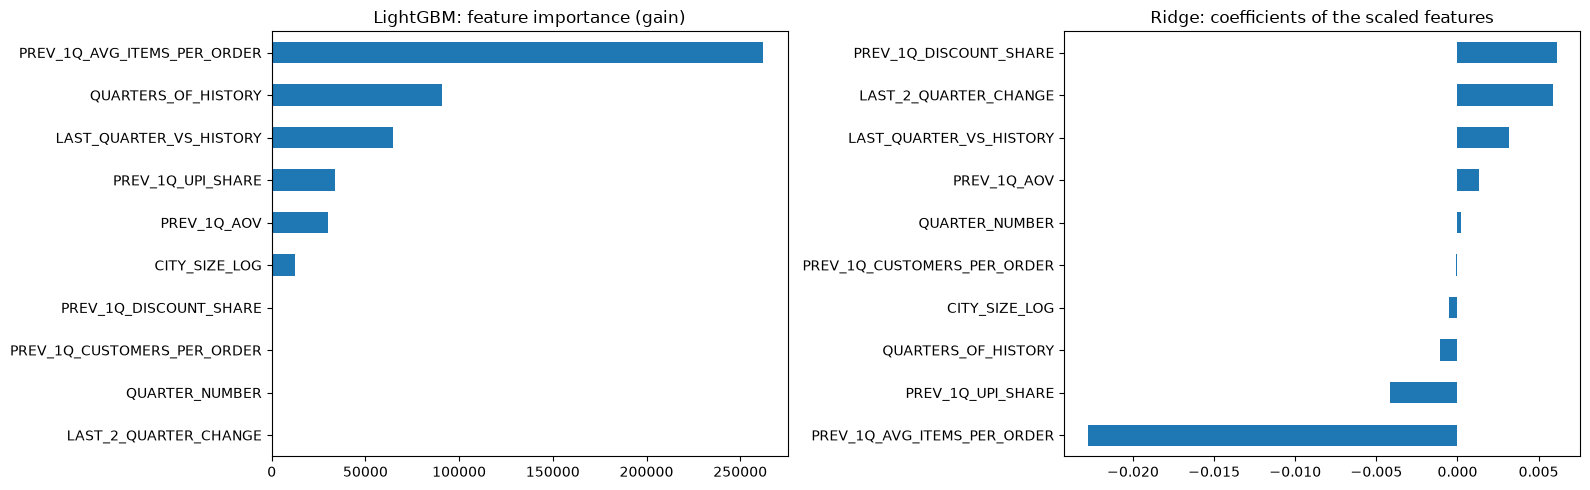

In [41]:
# lets check which features the models used
lightgbm_importance = pd.Series(lightgbm_model.booster_.feature_importance('gain'), index=FEATURE_COLUMNS).sort_values()
ridge_coefficients = pd.Series(ridge_model.coef_, index=FEATURE_COLUMNS).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
lightgbm_importance.plot(kind='barh', ax=ax[0], title='LightGBM: feature importance (gain)')
ridge_coefficients.plot(kind='barh', ax=ax[1], title='Ridge: coefficients of the scaled features')
plt.tight_layout()
plt.show()

##### LightGBM importance shows how much each feature helped the trees, and the Ridge coefficients show the direction of each scaled feature. Features near zero did not help the prediction.

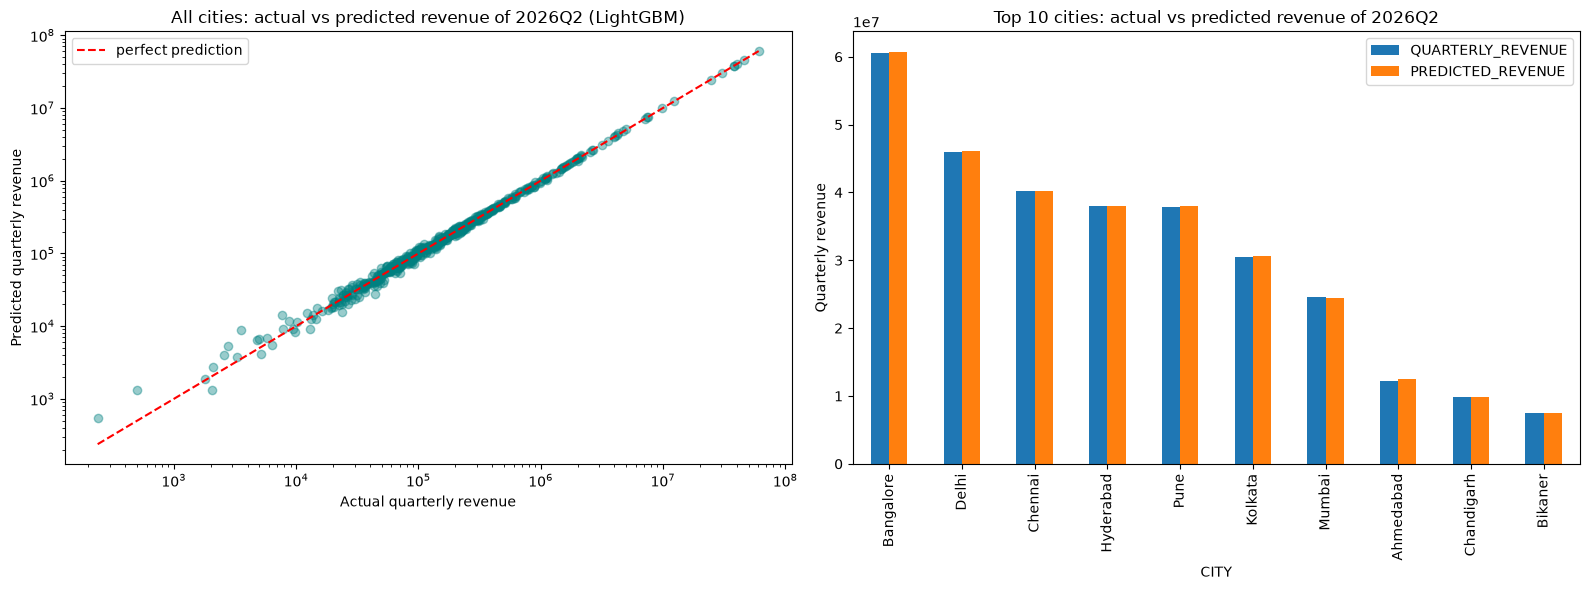

In [42]:
# lets compare the actual and the predicted revenue of the test quarter
final_predictions = test_predictions[final_model_name]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: every city (log scale, because the cities are very different in size)
ax[0].scatter(test_data['QUARTERLY_REVENUE'], final_predictions, alpha=0.4, color='teal')
axis_limit = [test_data['QUARTERLY_REVENUE'].clip(lower=1).min(), test_data['QUARTERLY_REVENUE'].max()]
ax[0].plot(axis_limit, axis_limit, color='red', linestyle='--', label='perfect prediction')
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_title(f'All cities: actual vs predicted revenue of {TEST_QUARTER} ({final_model_name})')
ax[0].set_xlabel('Actual quarterly revenue')
ax[0].set_ylabel('Predicted quarterly revenue')
ax[0].legend()

# Chart 2: the top 10 cities
top_10_test_cities = test_data.nlargest(10, 'QUARTERLY_REVENUE').copy()
top_10_test_cities['PREDICTED_REVENUE'] = final_predictions.loc[top_10_test_cities.index]
top_10_plot_data = top_10_test_cities.set_index('CITY')[['QUARTERLY_REVENUE', 'PREDICTED_REVENUE']]
top_10_plot_data.plot(kind='bar', ax=ax[1], title=f'Top 10 cities: actual vs predicted revenue of {TEST_QUARTER}')
ax[1].set_ylabel('Quarterly revenue')

plt.tight_layout()
plt.show()

In [43]:
# lets predict the next quarter for every city with the final model and prepare the recommendation table
# 1 the final model learns again from all the quarters with a known revenue (train + validation + test)
all_labelled_data = pd.concat([train_data, validation_data, test_data])

if final_model_name == 'Ridge':
    final_scaler = StandardScaler()
    X_all_scaled = final_scaler.fit_transform(all_labelled_data[FEATURE_COLUMNS])
    final_ridge_model = Ridge(alpha=1.0)
    final_ridge_model.fit(X_all_scaled, all_labelled_data['REVENUE_GROWTH_RATIO'], sample_weight=all_labelled_data['BASE_QUARTER_REVENUE'])
    forecast_growth_ratio = final_ridge_model.predict(final_scaler.transform(forecast_data[FEATURE_COLUMNS]))
elif final_model_name == 'LightGBM':
    final_lightgbm_model = lgb.LGBMRegressor(
        n_estimators=lightgbm_model.best_iteration_, learning_rate=0.03, num_leaves=7, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1
    )
    final_lightgbm_model.fit(all_labelled_data[FEATURE_COLUMNS], all_labelled_data['REVENUE_GROWTH_RATIO'], sample_weight=all_labelled_data['BASE_QUARTER_REVENUE'])
    forecast_growth_ratio = final_lightgbm_model.predict(forecast_data[FEATURE_COLUMNS])
elif final_model_name == 'Last quarter':
    forecast_growth_ratio = forecast_data['LAST_QUARTER_VS_HISTORY'].values
else:
    forecast_growth_ratio = np.ones(len(forecast_data))

# 2 the predicted revenue of the next quarter
city_forecast = forecast_data[['CITY', 'DAYS_IN_QUARTER', 'BASE_QUARTER_REVENUE']].copy()
city_forecast['FORECAST_REVENUE'] = np.clip(forecast_growth_ratio, 0, None) * city_forecast['BASE_QUARTER_REVENUE']

# 3 compare with the revenue of the last quarter
last_quarter_revenue = quarterly_city_revenue[quarterly_city_revenue['ORDER_QUARTER'] == LAST_QUARTER][['CITY', 'REVENUE_PER_DAY']]
last_quarter_revenue = last_quarter_revenue.rename(columns={'REVENUE_PER_DAY': 'LAST_QUARTER_REVENUE_PER_DAY'})
city_forecast = city_forecast.merge(last_quarter_revenue, on='CITY', how='left')
city_forecast['FORECAST_REVENUE_PER_DAY'] = city_forecast['FORECAST_REVENUE'] / city_forecast['DAYS_IN_QUARTER']
city_forecast['CHANGE_PCT'] = (city_forecast['FORECAST_REVENUE_PER_DAY'] / city_forecast['LAST_QUARTER_REVENUE_PER_DAY'] - 1) * 100
city_forecast['SHARE_OF_FORECAST_PCT'] = city_forecast['FORECAST_REVENUE'] / city_forecast['FORECAST_REVENUE'].sum() * 100

# 4 the large error of the final model for the size of the city (in the test quarter 9 of 10 cities have a smaller error)
test_data['ABSOLUTE_ERROR_PCT'] = (test_data['QUARTERLY_REVENUE'] - final_predictions).abs() / test_data['QUARTERLY_REVENUE'].replace(0, np.nan) * 100
large_error_by_size = test_data.groupby('CITY_SIZE_GROUP')['ABSOLUTE_ERROR_PCT'].quantile(0.9)
city_forecast['CITY_SIZE_GROUP'] = city_forecast['CITY'].map(city_rank).apply(get_city_size_group)
city_forecast['LARGE_ERROR_PCT'] = city_forecast['CITY_SIZE_GROUP'].map(large_error_by_size)

# 5 a city is a growth or decline watch only when the change is bigger than the large error (a smaller change can be just random noise)
city_forecast['SIGNAL'] = 'Stable'
city_forecast.loc[city_forecast['CHANGE_PCT'] > city_forecast['LARGE_ERROR_PCT'], 'SIGNAL'] = 'Growth watch'
city_forecast.loc[city_forecast['CHANGE_PCT'] < -city_forecast['LARGE_ERROR_PCT'], 'SIGNAL'] = 'Decline watch'

show_columns = ['CITY', 'CITY_SIZE_GROUP', 'LAST_QUARTER_REVENUE_PER_DAY', 'FORECAST_REVENUE_PER_DAY', 'FORECAST_REVENUE', 'CHANGE_PCT', 'LARGE_ERROR_PCT', 'SIGNAL']
print(f"--- FORECAST FOR {FORECAST_QUARTER} (final model: {final_model_name}) ---")
print(f"Total forecast revenue of all cities: {format_number(city_forecast['FORECAST_REVENUE'].sum())}")
same_days_last_quarter_revenue = (city_forecast['LAST_QUARTER_REVENUE_PER_DAY'] * city_forecast['DAYS_IN_QUARTER']).sum()
print(f"Revenue of the same cities if the last quarter {LAST_QUARTER} continues for {int(city_forecast['DAYS_IN_QUARTER'].iloc[0])} days: {format_number(same_days_last_quarter_revenue)}")
print("\n--- TOP 10 CITIES BY FORECAST REVENUE ---")
print(city_forecast.nlargest(10, 'FORECAST_REVENUE')[show_columns].to_string(index=False))
print("\n--- NUMBER OF CITIES BY SIGNAL ---")
print(city_forecast.groupby(['CITY_SIZE_GROUP', 'SIGNAL']).size().unstack(fill_value=0).reindex(CITY_SIZE_ORDER).to_string())
print("\n--- BIGGEST GROWTH WATCH (top 50 cities only) ---")
print(city_forecast[(city_forecast['SIGNAL'] == 'Growth watch') & (city_forecast['CITY_SIZE_GROUP'] != 'Other cities')].nlargest(10, 'CHANGE_PCT')[show_columns].to_string(index=False))
print("\n--- BIGGEST DECLINE WATCH (top 50 cities only) ---")
print(city_forecast[(city_forecast['SIGNAL'] == 'Decline watch') & (city_forecast['CITY_SIZE_GROUP'] != 'Other cities')].nsmallest(10, 'CHANGE_PCT')[show_columns].to_string(index=False))

--- FORECAST FOR 2026Q3 (final model: LightGBM) ---
Total forecast revenue of all cities: 506.25M
Revenue of the same cities if the last quarter 2026Q2 continues for 92 days: 505.49M

--- TOP 10 CITIES BY FORECAST REVENUE ---
      CITY CITY_SIZE_GROUP  LAST_QUARTER_REVENUE_PER_DAY  FORECAST_REVENUE_PER_DAY  FORECAST_REVENUE  CHANGE_PCT  LARGE_ERROR_PCT       SIGNAL
 Bangalore   Top 10 cities                    665,670.38                667,176.38     61,380,226.53        0.23             1.03       Stable
     Delhi   Top 10 cities                    505,545.70                506,038.84     46,555,572.90        0.10             1.03       Stable
   Chennai   Top 10 cities                    441,506.66                442,093.88     40,672,636.97        0.13             1.03       Stable
 Hyderabad   Top 10 cities                    417,613.12                417,432.46     38,403,786.45       -0.04             1.03       Stable
      Pune   Top 10 cities                    415,721.63   

##### `SIGNAL` is the recommendation flag: a city is a `Growth watch` or `Decline watch` only when the predicted change is bigger than the large error of its size group (`LARGE_ERROR_PCT` = the error which 9 of 10 cities stay below in the test quarter, one quarter only so it is a rough number). Everything else is `Stable`.
##### even with this rule about 1 city in 10 can be flagged only by random noise, so the watch list is a list of cities to check again with the next quarter of data, not a reason by itself to act. If no city is flagged, that is a valid result: it means no city moved by more than the noise.

In [44]:
from pathlib import Path
import joblib

if final_model_name == 'Ridge':
    print("Used Ridge")
    final_estimator = final_ridge_model
    saved_scaler = final_scaler
elif final_model_name == 'LightGBM':
    print("used LightGBM")
    final_estimator = final_lightgbm_model
    saved_scaler = None
else:
    print("something wrong")
    final_estimator = None
    saved_scaler = None

model_artifact = {
    'model_name': final_model_name,
    'estimator': final_estimator,
    'scaler': saved_scaler,
    'feature_columns': list(FEATURE_COLUMNS),
    'target': 'REVENUE_GROWTH_RATIO',
    'forecast_formula': 'clip(predicted_growth_ratio, 0, None) * BASE_QUARTER_REVENUE',
}
model_path = Path.cwd() / 'city_revenue_forecast.joblib'
joblib.dump(model_artifact, model_path)
print(f'Final model artifact saved to: {model_path.resolve()}')

used LightGBM
Final model artifact saved to: C:\Users\mrbis\OneDrive\Desktop\career_learning\zomato_food_project\swiggy_dbt\analyses\notebook\city_revenue_forecast.joblib
